**Environment Setup and Library Configuration**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, pearsonr

# Professional visualization theme
sns.set_theme(style="whitegrid")
plt.style.use("seaborn-v0_8")

plt.rcParams.update({
    'figure.figsize': (9,6),
    'axes.titlesize': 16,
    'axes.labelsize': 13,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'font.family': 'sans-serif'
})

**Data Loading and Integration**

In [2]:
df1 = pd.read_csv(r'C:\Users\Marvella\YEAR 3\FYP\Exploratory Data Analysis\animal_disease_world_dataset(1).csv', dtype=str)
df2 = pd.read_csv(r'C:\Users\Marvella\YEAR 3\FYP\Exploratory Data Analysis\animal_disease_world_dataset(2).csv', dtype=str)
df3 = pd.read_csv(r'C:\Users\Marvella\YEAR 3\FYP\Exploratory Data Analysis\animal_disease_world_dataset(3).csv', dtype=str)
df4 = pd.read_csv(r'C:\Users\Marvella\YEAR 3\FYP\Exploratory Data Analysis\animal_disease_world_dataset(4).csv', dtype=str)

print("Dataset 1 Shape:", df1.shape)
print("Dataset 2 Shape:", df2.shape)
print("Dataset 3 Shape:", df3.shape)
print("Dataset 4 Shape:", df4.shape)

Dataset 1 Shape: (431, 22)
Dataset 2 Shape: (40000, 24)
Dataset 3 Shape: (14000, 24)
Dataset 4 Shape: (30000, 24)


In [3]:
df = pd.read_csv(r'C:\Users\Marvella\YEAR 3\FYP\Exploratory Data Analysis\Data Pre-processing\animal_disease_merged_cleaned.csv')
print("Merged Dataset Shape:", df.shape)

Merged Dataset Shape: (59314, 30)


**Dataset Exploration and Column-Level Analysis**

In [4]:
def explore_dataset(df, name):
    print(f"\n================= {name} =================")
    print("Shape:", df.shape)
    
    print("\nPreview:")
    display(df.head())
    
    print("\nData Types & Info:")
    df.info()
    
    print("\nMissing Values:")
    display(df.isnull().sum())
    
    print("\nDuplicate Records:", df.duplicated().sum())
    
    print("\nUnique Values Per Column:")
    display(df.nunique())
    
    # Detailed column discussion
    print("\n--- Column-Level Summary ---")
    for col in df.columns:
        print(f"\nColumn: {col}")
        print("Data Type:", df[col].dtype)
        print("Unique Values:", df[col].nunique())
        print("Sample Values:", df[col].unique()[:5])

In [5]:
explore_dataset(df1, "Dataset 1")


================= Dataset 1 =================
Shape: (431, 22)

Preview:


,Animal_Type,Breed,Age,Gender,Weight,Symptom_1,Symptom_2,Symptom_3,Symptom_4,Duration,...,Diarrhea,Coughing,Labored_Breathing,Lameness,Skin_Lesions,Nasal_Discharge,Eye_Discharge,Body_Temperature,Heart_Rate,Disease_Prediction
0,Dog,Labrador,4,Male,25.0,Fever,Lethargy,Appetite Loss,Vomiting,3 days,...,No,No,No,No,No,No,No,39.5°C,120,Parvovirus
1,Cat,Siamese,2,Female,4.5,Coughing,Sneezing,Eye Discharge,Nasal Discharge,1 week,...,No,Yes,No,No,No,Yes,Yes,38.9°C,150,Upper Respiratory Infection
2,Cow,Holstein,3,Female,600.0,Fever,Nasal Discharge,Labored Breathing,Coughing,5 days,...,No,Yes,Yes,No,No,Yes,No,40.1°C,90,Foot and Mouth Disease
3,Dog,Beagle,1,Male,10.0,Diarrhea,Vomiting,Lethargy,Appetite Loss,2 days,...,Yes,No,No,No,No,No,No,39.2°C,130,Gastroenteritis
4,Cat,Persian,5,Male,3.8,Lethargy,Appetite Loss,Skin Lesions,No,2 weeks,...,No,No,No,No,Yes,No,No,38.7°C,160,Fungal Infection



Data Types & Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 431 entries, 0 to 430
Data columns (total 22 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Animal_Type         431 non-null    object
 1   Breed               431 non-null    object
 2   Age                 431 non-null    object
 3   Gender              431 non-null    object
 4   Weight              431 non-null    object
 5   Symptom_1           431 non-null    object
 6   Symptom_2           431 non-null    object
 7   Symptom_3           431 non-null    object
 8   Symptom_4           431 non-null    object
 9   Duration            431 non-null    object
 10  Appetite_Loss       431 non-null    object
 11  Vomiting            431 non-null    object
 12  Diarrhea            431 non-null    object
 13  Coughing            431 non-null    object
 14  Labored_Breathing   431 non-null    object
 15  Lameness            431 non-null    object
 16  Skin_L

Animal_Type           0
Breed                 0
Age                   0
Gender                0
Weight                0
Symptom_1             0
Symptom_2             0
Symptom_3             0
Symptom_4             0
Duration              0
Appetite_Loss         0
Vomiting              0
Diarrhea              0
Coughing              0
Labored_Breathing     0
Lameness              0
Skin_Lesions          0
Nasal_Discharge       0
Eye_Discharge         0
Body_Temperature      0
Heart_Rate            0
Disease_Prediction    0
dtype: int64


Duplicate Records: 10

Unique Values Per Column:


Animal_Type             8
Breed                 120
Age                    16
Gender                  2
Weight                110
Symptom_1              16
Symptom_2              20
Symptom_3              18
Symptom_4              23
Duration               12
Appetite_Loss           2
Vomiting                2
Diarrhea                2
Coughing                2
Labored_Breathing       2
Lameness                2
Skin_Lesions            2
Nasal_Discharge         2
Eye_Discharge           2
Body_Temperature       19
Heart_Rate             61
Disease_Prediction    139
dtype: int64


--- Column-Level Summary ---

Column: Animal_Type
Data Type: object
Unique Values: 8
Sample Values: ['Dog' 'Cat' 'Cow' 'Horse' 'Rabbit']

Column: Breed
Data Type: object
Unique Values: 120
Sample Values: ['Labrador' 'Siamese' 'Holstein' 'Beagle' 'Persian']

Column: Age
Data Type: object
Unique Values: 16
Sample Values: ['4' '2' '3' '1' '5']

Column: Gender
Data Type: object
Unique Values: 2
Sample Values: ['Male' 'Female']

Column: Weight
Data Type: object
Unique Values: 110
Sample Values: ['25.0' '4.5' '600.0' '10.0' '3.8']

Column: Symptom_1
Data Type: object
Unique Values: 16
Sample Values: ['Fever' 'Coughing' 'Diarrhea' 'Lethargy' 'Lameness']

Column: Symptom_2
Data Type: object
Unique Values: 20
Sample Values: ['Lethargy' 'Sneezing' 'Nasal Discharge' 'Vomiting' 'Appetite Loss']

Column: Symptom_3
Data Type: object
Unique Values: 18
Sample Values: ['Appetite Loss' 'Eye Discharge' 'Labored Breathing' 'Lethargy'
 'Skin Lesions']

Column: Symptom_4
Data Type: object
Unique Values: 23

In [6]:
explore_dataset(df2, "Dataset 2")


================= Dataset 2 =================
Shape: (40000, 24)

Preview:


,Species,Breed,Age,Gender,Weight,Symptom_1,Symptom_2,Symptom_3,Symptom_4,Duration,...,Labored_Breathing,Lameness,Skin_Lesions,Nasal_Discharge,Eye_Discharge,Body_Temperature,Heart_Rate,Disease_Prediction,Treatment,Description
0,"Bird,Parrot,9,Male,134.31,Lethargy,Coughing,Se...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Cow,Jersey,9,Male,129.58,Pain,Coughing,Weight Loss,Ulcers,7 days,...,No,Yes,No,Yes,No,40.8,132,Viral Infection,Supportive Care,Highly contagious viral disease
2,Fish,Goldfish,3,Male,396.93,Pain,Coughing,Swelling,Dehydration,25 days,...,No,No,Yes,No,Yes,39.3,83,Septicemia,IV Antibiotics,Life-threatening bloodstream infection
3,Shark,Great White,15,Female,162.33,Fever,Diarrhea,Weight Loss,Anemia,53 days,...,Yes,Yes,No,Yes,No,37.8,157,Parasitic Infestation,Antiparasitic Drugs,Internal or external parasite overload
4,Cow,Jersey,8,Female,448.33,Loss of Balance,Sneezing,Bleeding,Anemia,9 days,...,Yes,Yes,No,Yes,No,37.7,159,Parasitic Infestation,Antiparasitic Drugs,Internal or external parasite overload



Data Types & Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Species             40000 non-null  object
 1   Breed               22886 non-null  object
 2   Age                 22886 non-null  object
 3   Gender              22886 non-null  object
 4   Weight              22886 non-null  object
 5   Symptom_1           22886 non-null  object
 6   Symptom_2           22886 non-null  object
 7   Symptom_3           22886 non-null  object
 8   Symptom_4           22886 non-null  object
 9   Duration            22886 non-null  object
 10  Appetite_Loss       22886 non-null  object
 11  Vomiting            22886 non-null  object
 12  Diarrhea            22886 non-null  object
 13  Coughing            22886 non-null  object
 14  Labored_Breathing   22886 non-null  object
 15  Lameness            22886 non-null  object
 16  Sk

Species                   0
Breed                 17114
Age                   17114
Gender                17114
Weight                17114
Symptom_1             17114
Symptom_2             17114
Symptom_3             17114
Symptom_4             17114
Duration              17114
Appetite_Loss         17114
Vomiting              17114
Diarrhea              17114
Coughing              17114
Labored_Breathing     17114
Lameness              17114
Skin_Lesions          17114
Nasal_Discharge       17114
Eye_Discharge         17114
Body_Temperature      17114
Heart_Rate            17114
Disease_Prediction    17114
Treatment             17114
Description           17114
dtype: int64


Duplicate Records: 0

Unique Values Per Column:


Species               17126
Breed                    24
Age                      20
Gender                    2
Weight                19091
Symptom_1                 4
Symptom_2                 4
Symptom_3                 4
Symptom_4                 4
Duration                 60
Appetite_Loss             2
Vomiting                  2
Diarrhea                  2
Coughing                  2
Labored_Breathing         2
Lameness                  2
Skin_Lesions              2
Nasal_Discharge           2
Eye_Discharge             2
Body_Temperature         71
Heart_Rate              141
Disease_Prediction        5
Treatment                 5
Description               5
dtype: int64


--- Column-Level Summary ---

Column: Species
Data Type: object
Unique Values: 17126
Sample Values: ['Bird,Parrot,9,Male,134.31,Lethargy,Coughing,Seizures,Dehydration,2 days,Yes,Yes,Yes,Yes,Yes,No,Yes,No,No,40.7,41,Bacterial Pneumonia,"Antibiotics, Oxygen Therapy",Severe bacterial infection of the respiratory tract'
 'Cow' 'Fish' 'Shark'
 'Shark,Hammerhead,1,Male,409.19,Pain,Diarrhea,Weight Loss,Paralysis,28 days,Yes,No,Yes,No,Yes,Yes,No,Yes,Yes,37.6,81,Gastroenteritis,"Fluids, Probiotics",Inflammation of stomach and intestines']

Column: Breed
Data Type: object
Unique Values: 24
Sample Values: [nan 'Jersey' 'Goldfish' 'Great White' 'Arabian']

Column: Age
Data Type: object
Unique Values: 20
Sample Values: [nan '9' '3' '15' '8']

Column: Gender
Data Type: object
Unique Values: 2
Sample Values: [nan 'Male' 'Female']

Column: Weight
Data Type: object
Unique Values: 19091
Sample Values: [nan '129.58' '396.93' '162.33' '448.33']

Column: Symptom_1
Data Type: object
Unique Values: 4
Sample

In [7]:
explore_dataset(df3, "Dataset 3")


================= Dataset 3 =================
Shape: (14000, 24)

Preview:


,Species,Breed,Age,Gender,Weight,Symptom_1,Symptom_2,Symptom_3,Symptom_4,Duration,...,Labored_Breathing,Lameness,Skin_Lesions,Nasal_Discharge,Eye_Discharge,Body_Temperature,Heart_Rate,Disease_Prediction,Treatment,Description
0,"Horse,Arabian,7,Female,373.01,Cold extremities...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"Shark,Hammerhead,2,Male,588.69,Persistent feve...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,"Cow,Jersey,20,Female,623.48,Intermittent diarr...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"Dolphin,Bottlenose,19,Male,73.46,Generalized m...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,"Turtle,Red-eared Slider,5,Male,214.63,Abdomina...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Data Types & Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14000 entries, 0 to 13999
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Species             14000 non-null  object
 1   Breed               0 non-null      object
 2   Age                 0 non-null      object
 3   Gender              0 non-null      object
 4   Weight              0 non-null      object
 5   Symptom_1           0 non-null      object
 6   Symptom_2           0 non-null      object
 7   Symptom_3           0 non-null      object
 8   Symptom_4           0 non-null      object
 9   Duration            0 non-null      object
 10  Appetite_Loss       0 non-null      object
 11  Vomiting            0 non-null      object
 12  Diarrhea            0 non-null      object
 13  Coughing            0 non-null      object
 14  Labored_Breathing   0 non-null      object
 15  Lameness            0 non-null      object
 16  Sk

Species                   0
Breed                 14000
Age                   14000
Gender                14000
Weight                14000
Symptom_1             14000
Symptom_2             14000
Symptom_3             14000
Symptom_4             14000
Duration              14000
Appetite_Loss         14000
Vomiting              14000
Diarrhea              14000
Coughing              14000
Labored_Breathing     14000
Lameness              14000
Skin_Lesions          14000
Nasal_Discharge       14000
Eye_Discharge         14000
Body_Temperature      14000
Heart_Rate            14000
Disease_Prediction    14000
Treatment             14000
Description           14000
dtype: int64


Duplicate Records: 0

Unique Values Per Column:


Species               14000
Breed                     0
Age                       0
Gender                    0
Weight                    0
Symptom_1                 0
Symptom_2                 0
Symptom_3                 0
Symptom_4                 0
Duration                  0
Appetite_Loss             0
Vomiting                  0
Diarrhea                  0
Coughing                  0
Labored_Breathing         0
Lameness                  0
Skin_Lesions              0
Nasal_Discharge           0
Eye_Discharge             0
Body_Temperature          0
Heart_Rate                0
Disease_Prediction        0
Treatment                 0
Description               0
dtype: int64


--- Column-Level Summary ---

Column: Species
Data Type: object
Unique Values: 14000
Sample Values: ['Horse,Arabian,7,Female,373.01,Cold extremities,Marked lethargy,Sudden collapse episodes,Generalized malaise,9 days,Yes,No,No,Yes,Yes,Yes,Yes,No,Yes,37.3°C,56,Septicemia,"Emergency hospitalization with aggressive intravenous antimicrobial therapy, fluid resuscitation, hemodynamic stabilization, blood culture diagnostics, and continuous intensive care monitoring.","An acute, life-threatening systemic inflammatory syndrome resulting from bloodstream invasion by pathogenic organisms or toxins, rapidly progressing to multi-organ dysfunction."'
 'Shark,Hammerhead,2,Male,588.69,Persistent fever spikes,Chest discomfort,Exercise intolerance,Rapid shallow breathing,23 days,Yes,No,No,Yes,No,No,Yes,No,No,39.3°C,110,Bacterial Pneumonia,"Extended-course broad-spectrum antimicrobial therapy guided by culture and sensitivity testing, oxygen supplementation, nebulization, anti-inflammatory medication,

In [8]:
explore_dataset(df4, "Dataset 4")


================= Dataset 4 =================
Shape: (30000, 24)

Preview:


,Species,Breed,Age,Gender,Weight,Symptom_1,Symptom_2,Symptom_3,Symptom_4,Duration,...,Labored_Breathing,Lameness,Skin_Lesions,Nasal_Discharge,Eye_Discharge,Body_Temperature,Heart_Rate,Disease_Prediction,Treatment,Description
0,Horse,Quarter Horse,12,Male,753.8,Labored breathing,Persistent coughing,Nasal discharge,Exercise intolerance,3 days,...,No,No,Yes,Yes,Yes,41.3°C,84,Equine Colic Syndrome,Intensive supportive care including electrolyt...,A multifactorial disease process involving pat...
1,Lizard,Leopard Gecko,6,Male,315.35,Labored breathing,Persistent coughing,Nasal discharge,Exercise intolerance,1 days,...,Yes,Yes,No,No,Yes,41.1°C,142,Reptilian Respiratory Infection,Administration of species-appropriate antimicr...,A clinically significant veterinary disorder c...
2,Rabbit,Netherland Dwarf,3,Female,315.98,Labored breathing,Persistent coughing,Nasal discharge,Exercise intolerance,3 days,...,No,No,No,Yes,No,39.5°C,173,Rabbit Ear Mite Infestation,Multimodal treatment involving pathogen‑specif...,A complex pathological condition that affects ...
3,Cat,Maine Coon,1,Male,425.44,Labored breathing,Persistent coughing,Nasal discharge,Exercise intolerance,1 days,...,Yes,Yes,No,No,Yes,40.2°C,103,Feline Hyperthyroidism,Multimodal treatment involving pathogen‑specif...,A multifactorial disease process involving pat...
4,Dog,German Shepherd,20,Female,451.78,Muscle tremors,Loss of coordination,Behavioral changes,Seizure activity,16 days,...,No,Yes,No,No,Yes,41.0°C,86,Canine Atopic Dermatitis,Intensive supportive care including electrolyt...,A clinically significant veterinary disorder c...



Data Types & Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Species             30000 non-null  object
 1   Breed               30000 non-null  object
 2   Age                 30000 non-null  object
 3   Gender              30000 non-null  object
 4   Weight              30000 non-null  object
 5   Symptom_1           30000 non-null  object
 6   Symptom_2           30000 non-null  object
 7   Symptom_3           30000 non-null  object
 8   Symptom_4           30000 non-null  object
 9   Duration            30000 non-null  object
 10  Appetite_Loss       30000 non-null  object
 11  Vomiting            30000 non-null  object
 12  Diarrhea            30000 non-null  object
 13  Coughing            30000 non-null  object
 14  Labored_Breathing   30000 non-null  object
 15  Lameness            30000 non-null  object
 16  Sk

Species               0
Breed                 0
Age                   0
Gender                0
Weight                0
Symptom_1             0
Symptom_2             0
Symptom_3             0
Symptom_4             0
Duration              0
Appetite_Loss         0
Vomiting              0
Diarrhea              0
Coughing              0
Labored_Breathing     0
Lameness              0
Skin_Lesions          0
Nasal_Discharge       0
Eye_Discharge         0
Body_Temperature      0
Heart_Rate            0
Disease_Prediction    0
Treatment             0
Description           0
dtype: int64


Duplicate Records: 0

Unique Values Per Column:


Species                  10
Breed                    32
Age                      20
Gender                    2
Weight                24965
Symptom_1                 5
Symptom_2                 5
Symptom_3                 5
Symptom_4                 5
Duration                 21
Appetite_Loss             2
Vomiting                  2
Diarrhea                  2
Coughing                  2
Labored_Breathing         2
Lameness                  2
Skin_Lesions              2
Nasal_Discharge           2
Eye_Discharge             2
Body_Temperature         51
Heart_Rate              121
Disease_Prediction       99
Treatment                 4
Description               4
dtype: int64


--- Column-Level Summary ---

Column: Species
Data Type: object
Unique Values: 10
Sample Values: ['Horse' 'Lizard' 'Rabbit' 'Cat' 'Dog']

Column: Breed
Data Type: object
Unique Values: 32
Sample Values: ['Quarter Horse' 'Leopard Gecko' 'Netherland Dwarf' 'Maine Coon'
 'German Shepherd']

Column: Age
Data Type: object
Unique Values: 20
Sample Values: ['12' '6' '3' '1' '20']

Column: Gender
Data Type: object
Unique Values: 2
Sample Values: ['Male' 'Female']

Column: Weight
Data Type: object
Unique Values: 24965
Sample Values: ['753.8' '315.35' '315.98' '425.44' '451.78']

Column: Symptom_1
Data Type: object
Unique Values: 5
Sample Values: ['Labored breathing' 'Muscle tremors' 'Vomiting episodes' 'Weight loss'
 'Patchy hair loss']

Column: Symptom_2
Data Type: object
Unique Values: 5
Sample Values: ['Persistent coughing' 'Loss of coordination' 'Loose stool' 'Lethargy'
 'Skin irritation']

Column: Symptom_3
Data Type: object
Unique Values: 5
Sample Values: ['Nasal discharge' 'Behavioral c

In [9]:
explore_dataset(df, "Merged Dataset")


================= Merged Dataset =================
Shape: (59314, 30)

Preview:


,Species,Breed,Age,Gender,Weight,Symptom_1,Symptom_2,Symptom_3,Symptom_4,Duration,...,Heart_Rate,Disease_Prediction,Treatment,Description,Symptom_Count,Temp_Risk,Symptom_Risk,Critical_Risk,Dangerous_Level,Danger_Level_Category
0,Cow,Holstein,3,Female,524.63,Fever,Nasal Discharge,Labored Breathing,Coughing,5 days,...,90,Foot and Mouth Disease,Not_Recorded,Not_Recorded,3,0.62,0.375,0.5,52.25,High
1,Dog,Beagle,1,Male,10.00,Diarrhea,Vomiting,Lethargy,Appetite Loss,2 days,...,130,Gastroenteritis,Not_Recorded,Not_Recorded,2,0.44,0.250,0.0,29.50,Moderate
2,Horse,Thoroughbred,6,Female,500.00,Coughing,Labored Breathing,Nasal Discharge,Fever,10 days,...,85,Equine Influenza,Not_Recorded,Not_Recorded,3,0.56,0.375,0.5,49.25,Moderate
3,Dog,German Shepherd,3,Female,30.00,Lameness,Fever,Skin Lesions,Lethargy,7 days,...,110,Lyme Disease,Not_Recorded,Not_Recorded,2,0.46,0.250,0.5,40.50,Moderate
4,Dog,Bulldog,5,Male,23.00,Labored Breathing,Coughing,Nasal Discharge,Appetite Loss,6 days,...,115,Canine Distemper,Not_Recorded,Not_Recorded,3,0.60,0.375,0.5,51.25,High



Data Types & Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59314 entries, 0 to 59313
Data columns (total 30 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Species                59314 non-null  object 
 1   Breed                  59314 non-null  object 
 2   Age                    59314 non-null  int64  
 3   Gender                 59314 non-null  object 
 4   Weight                 59314 non-null  float64
 5   Symptom_1              59314 non-null  object 
 6   Symptom_2              59314 non-null  object 
 7   Symptom_3              59314 non-null  object 
 8   Symptom_4              59314 non-null  object 
 9   Duration               59314 non-null  object 
 10  Appetite_Loss          59314 non-null  int64  
 11  Vomiting               59314 non-null  int64  
 12  Diarrhea               59314 non-null  int64  
 13  Coughing               59314 non-null  int64  
 14  Labored_Breathing      59314 non-n

Species                  0
Breed                    0
Age                      0
Gender                   0
Weight                   0
Symptom_1                0
Symptom_2                0
Symptom_3                0
Symptom_4                0
Duration                 0
Appetite_Loss            0
Vomiting                 0
Diarrhea                 0
Coughing                 0
Labored_Breathing        0
Lameness                 0
Skin_Lesions             0
Nasal_Discharge          0
Eye_Discharge            0
Body_Temperature         0
Heart_Rate               0
Disease_Prediction       0
Treatment                0
Description              0
Symptom_Count            0
Temp_Risk                0
Symptom_Risk             0
Critical_Risk            0
Dangerous_Level          0
Danger_Level_Category    0
dtype: int64


Duplicate Records: 0

Unique Values Per Column:


Species                     16
Breed                      129
Age                         25
Gender                       2
Weight                   19300
Symptom_1                  117
Symptom_2                  119
Symptom_3                  119
Symptom_4                  126
Duration                    62
Appetite_Loss                2
Vomiting                     2
Diarrhea                     2
Coughing                     2
Labored_Breathing            2
Lameness                     2
Skin_Lesions                 2
Nasal_Discharge              2
Eye_Discharge                2
Body_Temperature            71
Heart_Rate                 141
Disease_Prediction         162
Treatment                   27
Description                 27
Symptom_Count                9
Temp_Risk                   51
Symptom_Risk                 9
Critical_Risk                3
Dangerous_Level            357
Danger_Level_Category        4
dtype: int64


--- Column-Level Summary ---

Column: Species
Data Type: object
Unique Values: 16
Sample Values: ['Cow' 'Dog' 'Horse' 'Cat' 'Rabbit']

Column: Breed
Data Type: object
Unique Values: 129
Sample Values: ['Holstein' 'Beagle' 'Thoroughbred' 'German Shepherd' 'Bulldog']

Column: Age
Data Type: int64
Unique Values: 25
Sample Values: [3 1 6 5 4]

Column: Gender
Data Type: object
Unique Values: 2
Sample Values: ['Female' 'Male']

Column: Weight
Data Type: float64
Unique Values: 19300
Sample Values: [524.63  10.   500.    30.    23.  ]

Column: Symptom_1
Data Type: object
Unique Values: 117
Sample Values: ['Fever' 'Diarrhea' 'Coughing' 'Lameness' 'Labored Breathing']

Column: Symptom_2
Data Type: object
Unique Values: 119
Sample Values: ['Nasal Discharge' 'Vomiting' 'Labored Breathing' 'Fever' 'Coughing']

Column: Symptom_3
Data Type: object
Unique Values: 119
Sample Values: ['Labored Breathing' 'Lethargy' 'Nasal Discharge' 'Skin Lesions' 'Fever']

Column: Symptom_4
Data Type: object
Unique Va

In [10]:
print("\nRandom Sample Rows:")
display(df.sample(15))


Random Sample Rows:


,Species,Breed,Age,Gender,Weight,Symptom_1,Symptom_2,Symptom_3,Symptom_4,Duration,...,Heart_Rate,Disease_Prediction,Treatment,Description,Symptom_Count,Temp_Risk,Symptom_Risk,Critical_Risk,Dangerous_Level,Danger_Level_Category
53712,Goat,Boer,1,Male,52.31,Labored breathing,Persistent coughing,Nasal discharge,Exercise intolerance,21 days,...,107,Caprine Arthritis Encephalitis,Comprehensive veterinary management including ...,A complex pathological condition that affects ...,5,0.40,0.625,1.0,58.75,High
12238,Bird,Eagle,3,Female,0.08,Lethargy,Coughing,Bleeding,Anemia,9 days,...,98,Septicemia,IV Antibiotics,Life-threatening bloodstream infection,7,0.14,0.875,0.5,43.25,Moderate
40315,Dog,German Shepherd,18,Female,67.66,Labored breathing,Persistent coughing,Nasal discharge,Exercise intolerance,12 days,...,112,Canine Distemper Virus Infection,Intensive supportive care including electrolyt...,A clinically significant veterinary disorder c...,3,0.08,0.375,1.0,35.25,Moderate
20992,Bird,Eagle,3,Male,4.58,Appetite Loss,Diarrhea,Skin Lesions,Weakness,14 days,...,161,Parasitic Infestation,"Targeted antiparasitic therapy (e.g., ivermect...",A pathological state induced by internal or ex...,3,0.32,0.375,0.5,37.25,Moderate
25036,Bird,Parrot,25,Female,4.27,Delayed growth,Unthrifty body score,Chronic weight decline,Pot-bellied appearance,28 days,...,84,Parasitic Infestation,"Strategic antiparasitic protocol (ivermectin, ...",A parasitic burden compromising gastrointestin...,5,0.82,0.625,0.5,69.75,High
2858,Snake,Python,2,Female,10.54,Loss of Balance,Coughing,Bleeding,Ulcers,41 days,...,80,Septicemia,IV Antibiotics,Life-threatening bloodstream infection,5,0.20,0.625,0.5,38.75,Moderate
14173,Cat,Maine Coon,16,Female,7.51,Pain,Coughing,Swelling,Dehydration,23 days,...,113,Septicemia,IV Antibiotics,Life-threatening bloodstream infection,2,0.38,0.250,0.5,36.50,Moderate
1256,Dolphin,Bottlenose,14,Male,206.48,Fever,Coughing,Weight Loss,Paralysis,59 days,...,116,Bacterial Pneumonia,"Antibiotics, Oxygen Therapy",Severe bacterial infection of the respiratory ...,5,0.22,0.625,1.0,49.75,Moderate
22603,Dog,German Shepherd,10,Female,52.13,Generalized malaise,Marked lethargy,Weak peripheral pulses,Sudden collapse episodes,3 days,...,56,Septicemia,Emergency hospitalization with aggressive intr...,"An acute, life-threatening systemic inflammato...",4,0.36,0.500,0.5,43.00,Moderate
8463,Dog,German Shepherd,6,Female,72.28,Loss of Balance,Diarrhea,Swelling,Anemia,41 days,...,105,Viral Infection,Supportive Care,Highly contagious viral disease,4,0.00,0.500,0.0,15.00,Low


In [11]:
disease_counts = df['Disease_Prediction'].value_counts()
print("\n=== Disease Distribution ===")
for disease, count in disease_counts.items():
    print(f"{disease} - {count}")


=== Disease Distribution ===
Parasitic Infestation - 8941
Septicemia - 8932
Bacterial Pneumonia - 6722
Viral Infection - 1916
Gastroenteritis - 760
Dermatophytosis - 750
Rabbit Ear Mite Infestation  - 664
Canine Atopic Dermatitis  - 638
Lizard Dermal Fungal Infection  - 636
Rabbit Hemorrhagic Disease  - 636
Lizard Parasitic Infestation  - 634
Ichthyophthirius Multifiliis Infection  - 633
Avian Respiratory Mycoplasmosis  - 633
Fin Rot Bacterial Disease  - 631
Swim Bladder Disorder  - 629
Equine Gastric Ulcer Syndrome  - 622
Equine Laminitis Disorder  - 621
Bovine Mastitis  - 619
Reptile Vitamin A Deficiency  - 614
Fish Gill Fluke Infestation  - 610
Caprine Pneumonia Syndrome  - 606
Canine Parvoviral Enteritis  - 604
Goat Parasitic Enteritis  - 604
Feline Infectious Peritonitis  - 603
Snake Inclusion Body Disease  - 603
Snake Respiratory Infection  - 602
Equine Influenza Virus Infection  - 602
Avian Nutritional Deficiency Syndrome  - 602
Bovine Ketosis Disorder  - 601
Bovine Respiratory

**Target Variable Distribution and Class Imbalance Analysis**

In [12]:
print("\n" + "="*60)
print("TARGET VARIABLE: DISEASE PREDICTION ANALYSIS")
print("="*60)

disease_counts = df['Disease_Prediction'].value_counts()
print("\n=== Disease Distribution ===")
for disease, count in disease_counts.items():
    print(f"{disease} - {count}")

print("\n===== CLASS DISTRIBUTION ANALYSIS =====")
class_distribution = df['Disease_Prediction'].value_counts()
print(class_distribution)

print("\nClass Imbalance Ratio:")
imbalance_ratio = class_distribution.max() / class_distribution.min()
print(f"Imbalance Ratio: {round(imbalance_ratio, 2)}:1")


TARGET VARIABLE: DISEASE PREDICTION ANALYSIS

=== Disease Distribution ===
Parasitic Infestation - 8941
Septicemia - 8932
Bacterial Pneumonia - 6722
Viral Infection - 1916
Gastroenteritis - 760
Dermatophytosis - 750
Rabbit Ear Mite Infestation  - 664
Canine Atopic Dermatitis  - 638
Lizard Dermal Fungal Infection  - 636
Rabbit Hemorrhagic Disease  - 636
Lizard Parasitic Infestation  - 634
Ichthyophthirius Multifiliis Infection  - 633
Avian Respiratory Mycoplasmosis  - 633
Fin Rot Bacterial Disease  - 631
Swim Bladder Disorder  - 629
Equine Gastric Ulcer Syndrome  - 622
Equine Laminitis Disorder  - 621
Bovine Mastitis  - 619
Reptile Vitamin A Deficiency  - 614
Fish Gill Fluke Infestation  - 610
Caprine Pneumonia Syndrome  - 606
Canine Parvoviral Enteritis  - 604
Goat Parasitic Enteritis  - 604
Feline Infectious Peritonitis  - 603
Snake Inclusion Body Disease  - 603
Snake Respiratory Infection  - 602
Equine Influenza Virus Infection  - 602
Avian Nutritional Deficiency Syndrome  - 602
Bov

*Visualize disease distribution*

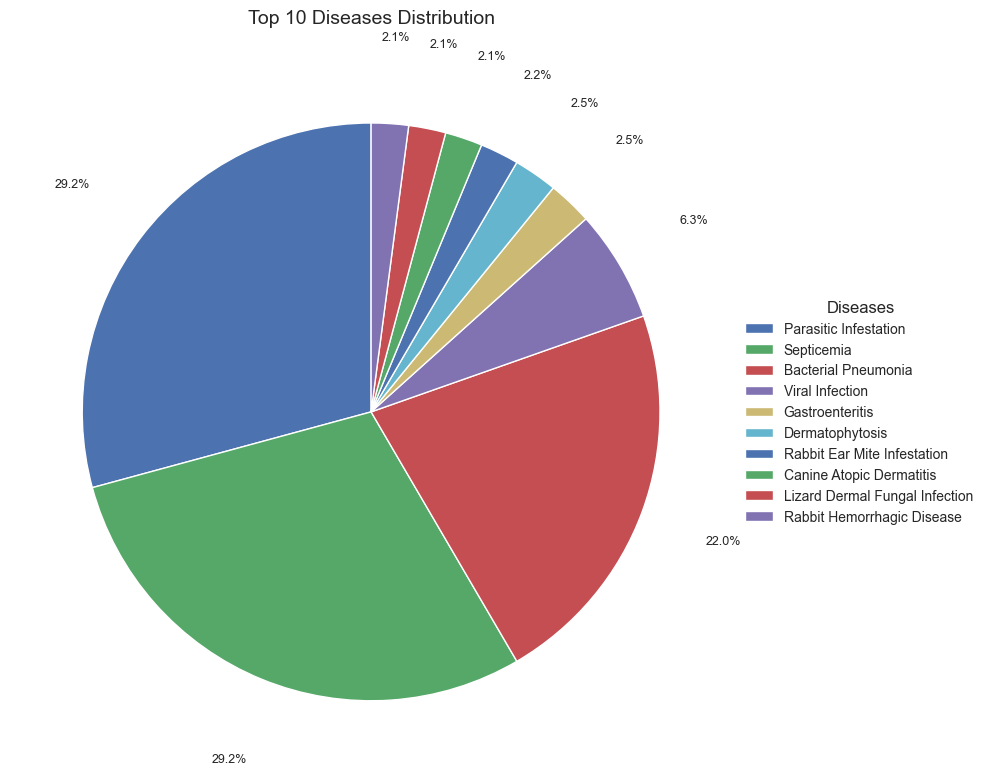

In [13]:
# Top 10 Diseases - Very simple with external percentages
plt.figure(figsize=(12, 8))

top_diseases = df['Disease_Prediction'].value_counts().head(10)

# Create pie chart
wedges, texts = plt.pie(
    top_diseases.values,
    startangle=90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1}
)

# Calculate percentages
total = sum(top_diseases.values)
percentages = [(value/total)*100 for value in top_diseases.values]

# Add simple percentage labels around the pie
for i, (wedge, percentage) in enumerate(zip(wedges, percentages)):
    ang = (wedge.theta2 - wedge.theta1)/2. + wedge.theta1
    y = np.sin(np.deg2rad(ang))
    x = np.cos(np.deg2rad(ang))
    
    # Place text at 1.3 radius
    plt.text(1.3*x, 1.3*y, f'{percentage:.1f}%', 
            ha='center', va='center', fontsize=9)

plt.title('Top 10 Diseases Distribution', fontsize=14, pad=20)
plt.legend(wedges, top_diseases.index, title="Diseases", 
          loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))
plt.tight_layout()
plt.show()

**Variable Categorization and Structural Summary**

In [14]:
print("\n" + "="*60)
print("VARIABLE CATEGORIZATION")
print("="*60)

categorical_cols = df.select_dtypes(include='object').columns.tolist()
numerical_cols = df.select_dtypes(include=['int64','float64','float32']).columns.tolist()

print("Categorical Variables:", categorical_cols)
print("Numerical Variables:", numerical_cols)

# Classify numerical variables into binary vs continuous
binary_cols = []
continuous_cols = []

for col in numerical_cols:
    unique_count = df[col].nunique()
    if unique_count <= 2:
        binary_cols.append(col)
    else:
        continuous_cols.append(col)

print("\nBinary Variables:", binary_cols)
print("Continuous Variables:", continuous_cols)


VARIABLE CATEGORIZATION
Categorical Variables: ['Species', 'Breed', 'Gender', 'Symptom_1', 'Symptom_2', 'Symptom_3', 'Symptom_4', 'Duration', 'Disease_Prediction', 'Treatment', 'Description', 'Danger_Level_Category']
Numerical Variables: ['Age', 'Weight', 'Appetite_Loss', 'Vomiting', 'Diarrhea', 'Coughing', 'Labored_Breathing', 'Lameness', 'Skin_Lesions', 'Nasal_Discharge', 'Eye_Discharge', 'Body_Temperature', 'Heart_Rate', 'Symptom_Count', 'Temp_Risk', 'Symptom_Risk', 'Critical_Risk', 'Dangerous_Level']

Binary Variables: ['Appetite_Loss', 'Vomiting', 'Diarrhea', 'Coughing', 'Labored_Breathing', 'Lameness', 'Skin_Lesions', 'Nasal_Discharge', 'Eye_Discharge']
Continuous Variables: ['Age', 'Weight', 'Body_Temperature', 'Heart_Rate', 'Symptom_Count', 'Temp_Risk', 'Symptom_Risk', 'Critical_Risk', 'Dangerous_Level']


In [15]:
# Summary table
variable_summary = pd.DataFrame({
    "Data Type": df.dtypes,
    "Missing Values": df.isnull().sum(),
    "Unique Values": df.nunique(),
    "Percentage Missing": (df.isnull().sum()/len(df)*100).round(2)
})

print("\nVariable Summary Table:")
display(variable_summary)


Variable Summary Table:


,Data Type,Missing Values,Unique Values,Percentage Missing
Species,object,0,16,0.0
Breed,object,0,129,0.0
Age,int64,0,25,0.0
Gender,object,0,2,0.0
Weight,float64,0,19300,0.0
Symptom_1,object,0,117,0.0
Symptom_2,object,0,119,0.0
Symptom_3,object,0,119,0.0
Symptom_4,object,0,126,0.0
Duration,object,0,62,0.0


**Descriptive Statistics Analysis**

*Numerical Descriptive Statistics*

In [16]:
print("\n" + "="*60)
print("DESCRIPTIVE STATISTICS")
print("="*60)

# Numerical Descriptive Statistics
print("\n=== Numerical Descriptive Statistics ===")
display(df[numerical_cols].describe().T)


DESCRIPTIVE STATISTICS

=== Numerical Descriptive Statistics ===


,count,mean,std,min,25%,50%,75%,max
Age,59314.0,11.026469,6.205160,1.00,6.000,11.00,16.000,25.00
Weight,59314.0,133.742050,182.615719,0.01,5.840,39.65,213.355,524.63
Appetite_Loss,59314.0,0.499983,0.500004,0.00,0.000,0.00,1.000,1.00
Vomiting,59314.0,0.498365,0.500002,0.00,0.000,0.00,1.000,1.00
Diarrhea,59314.0,0.500792,0.500004,0.00,0.000,1.00,1.000,1.00
Coughing,59314.0,0.499663,0.500004,0.00,0.000,0.00,1.000,1.00
Labored_Breathing,59314.0,0.503018,0.499995,0.00,0.000,1.00,1.000,1.00
Lameness,59314.0,0.497640,0.499999,0.00,0.000,0.00,1.000,1.00
Skin_Lesions,59314.0,0.500236,0.500004,0.00,0.000,1.00,1.000,1.00
Nasal_Discharge,59314.0,0.503827,0.499990,0.00,0.000,1.00,1.000,1.00


*Skewness and Kurtosis Assessment*

In [17]:
print("\n=== Skewness and Kurtosis Assessment ===")
skew_kurt = pd.DataFrame({
    "Skewness": df[numerical_cols].skew().round(3),
    "Kurtosis": df[numerical_cols].kurt().round(3)
})
display(skew_kurt)


=== Skewness and Kurtosis Assessment ===


,Skewness,Kurtosis
Age,0.119,-1.016
Weight,1.271,0.026
Appetite_Loss,0.000,-2.000
Vomiting,0.007,-2.000
Diarrhea,-0.003,-2.000
Coughing,0.001,-2.000
Labored_Breathing,-0.012,-2.000
Lameness,0.009,-2.000
Skin_Lesions,-0.001,-2.000
Nasal_Discharge,-0.015,-2.000


**Visual Exploration of Numerical Variables**

*Histograms only for continuous variables*


=== Continuous Variables Distribution ===


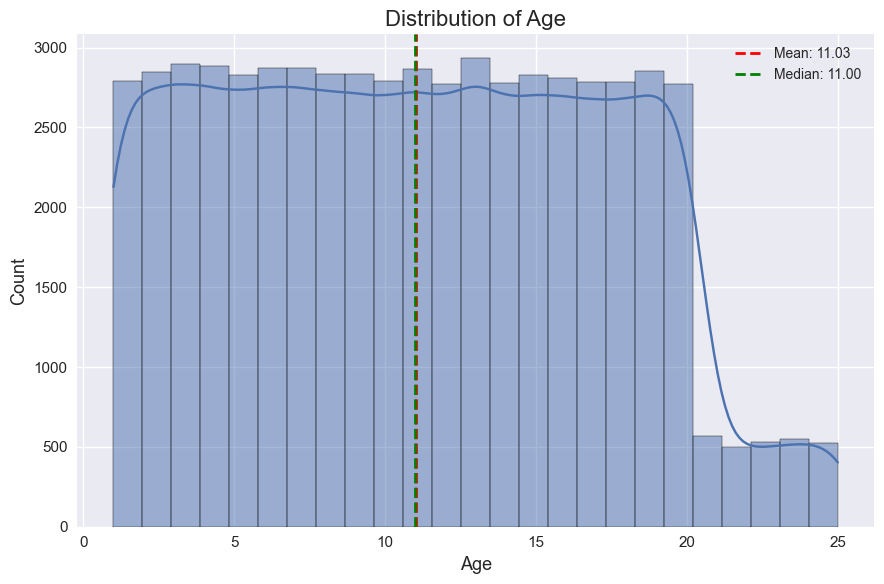

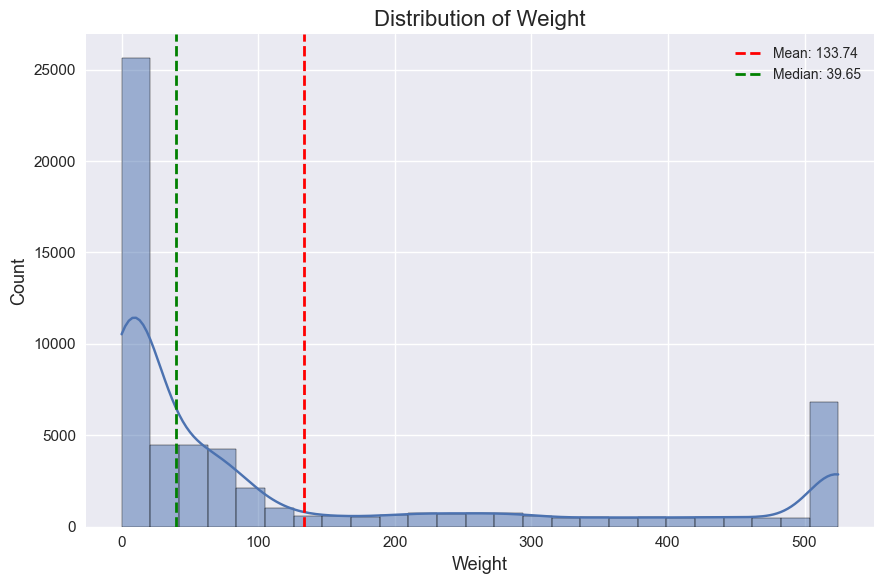

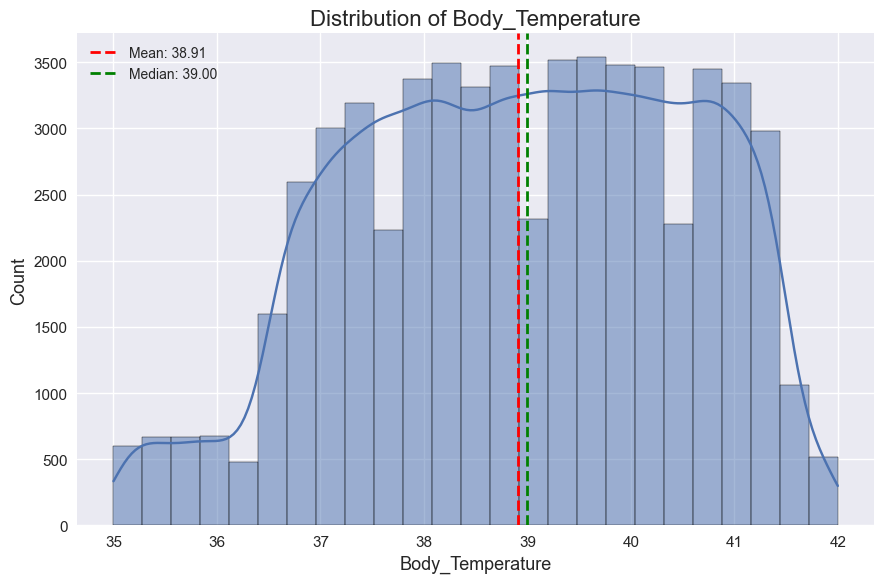

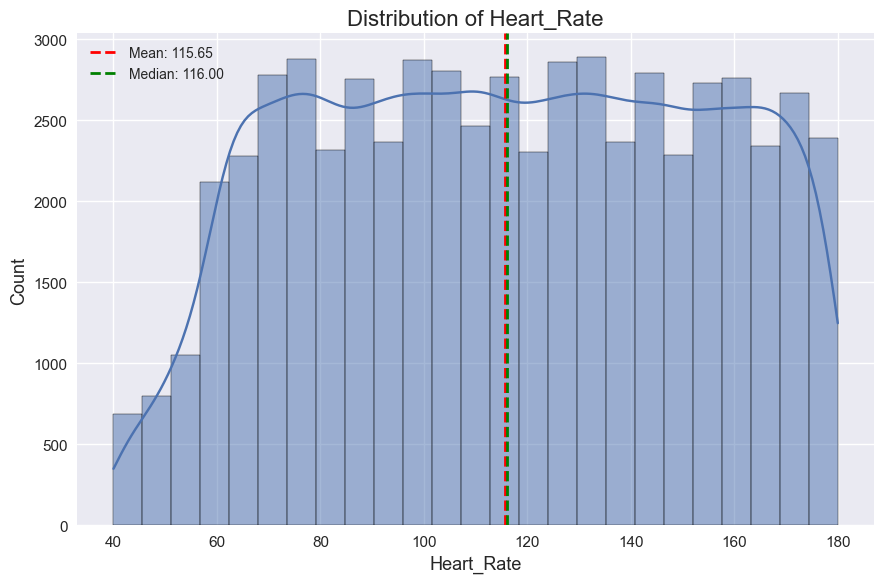

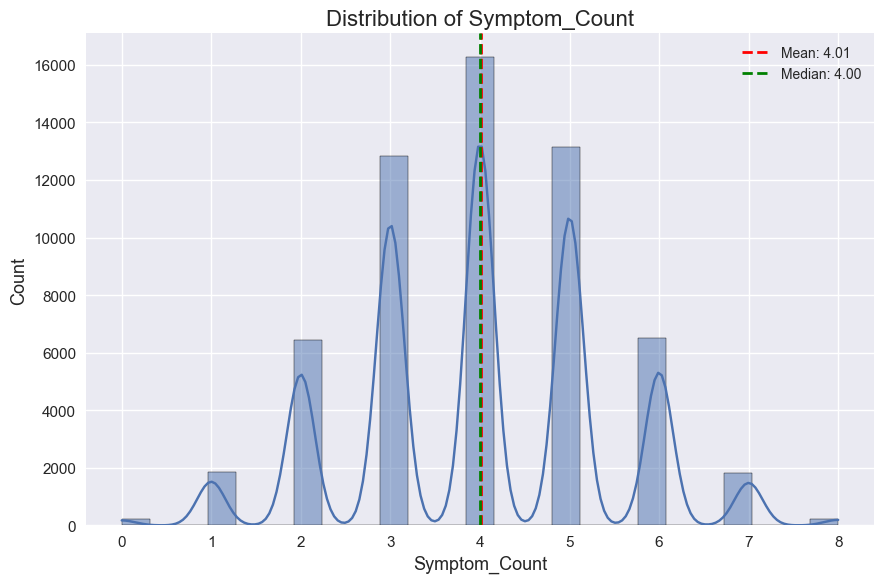

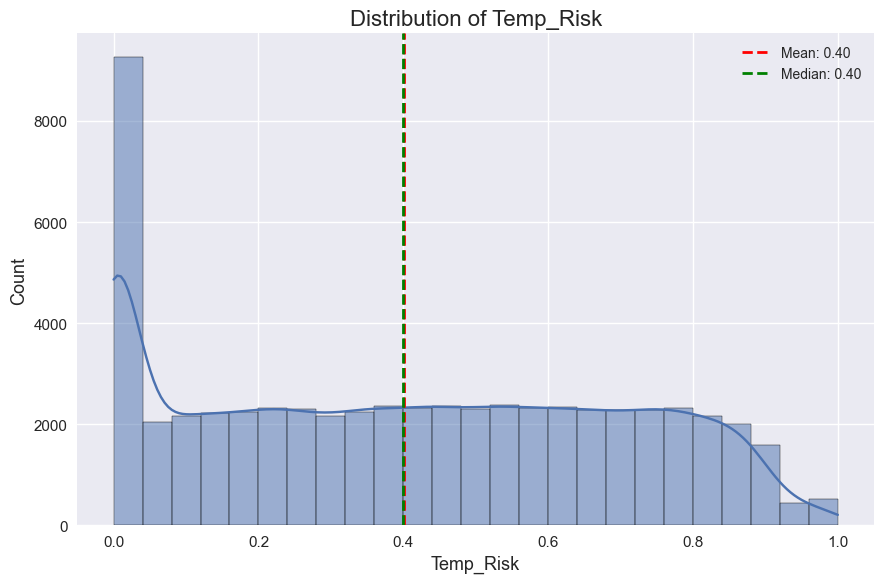

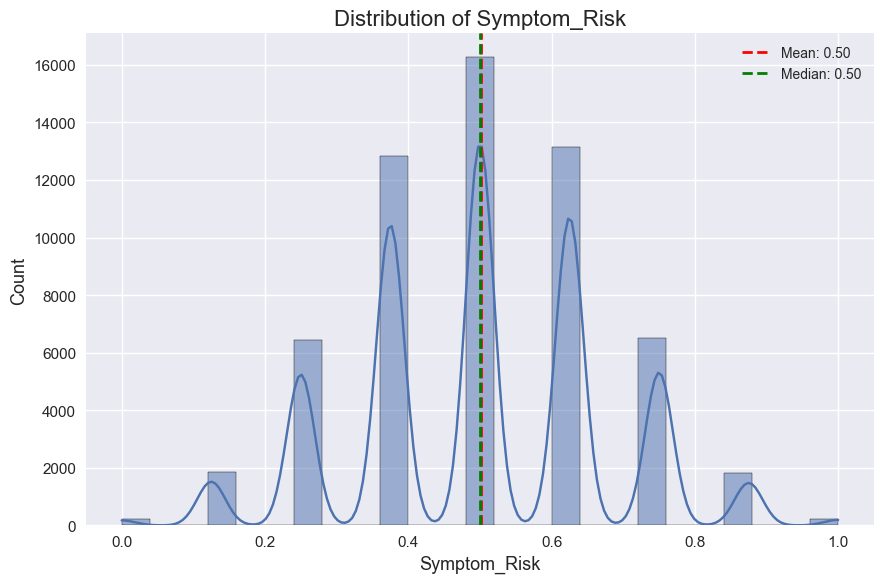

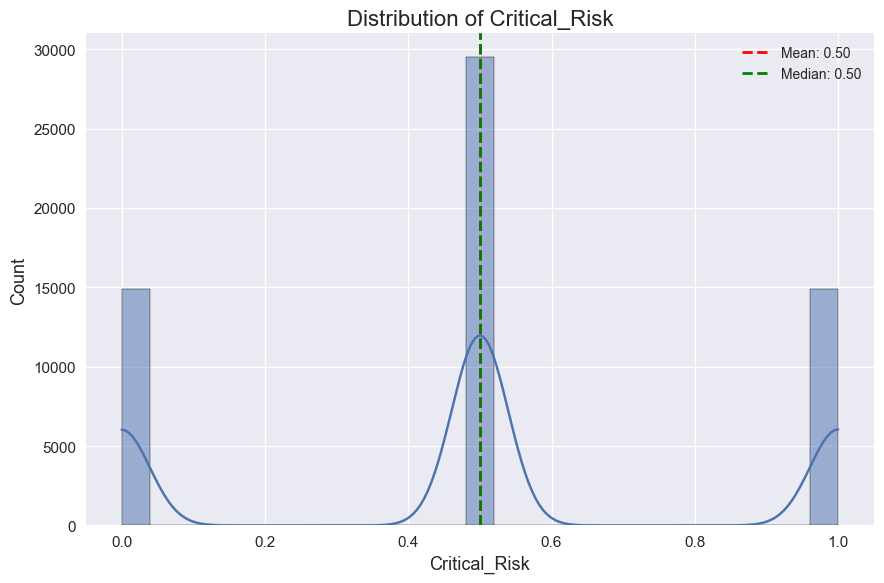

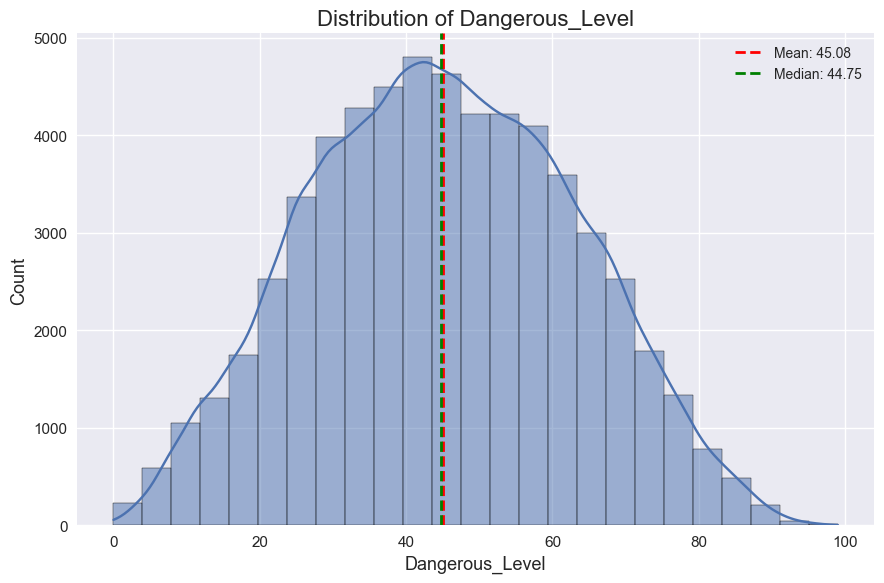

In [18]:
print("\n=== Continuous Variables Distribution ===")
for col in continuous_cols:
    plt.figure()
    sns.histplot(df[col].dropna(), bins=25, kde=True, color="#4C72B0", edgecolor="black")
    
    mean_val = df[col].mean()
    median_val = df[col].median()
    plt.axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f"Mean: {mean_val:.2f}")
    plt.axvline(median_val, color='green', linestyle='--', linewidth=2, label=f"Median: {median_val:.2f}")
    
    plt.title(f"Distribution of {col}")
    plt.legend()
    plt.tight_layout()
    plt.show()

*Bar plots for binary variables*


=== Binary Variables Distribution ===


C:\Users\Marvella\AppData\Local\Temp\ipykernel_19512\3802682654.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=counts.index.astype(str), y=counts.values, palette="Set2")


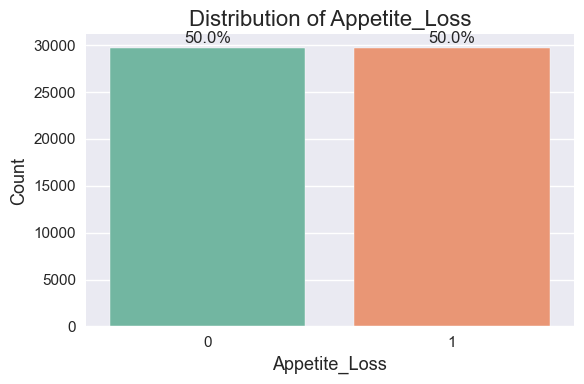

C:\Users\Marvella\AppData\Local\Temp\ipykernel_19512\3802682654.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=counts.index.astype(str), y=counts.values, palette="Set2")


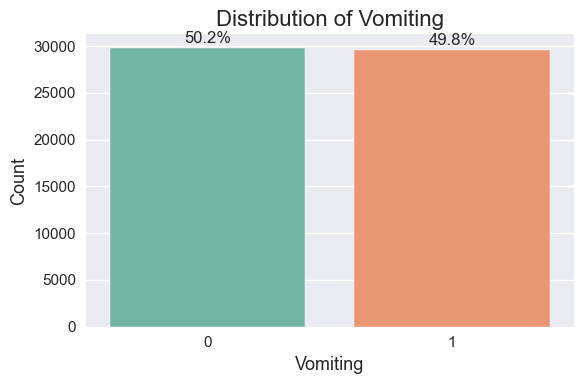

C:\Users\Marvella\AppData\Local\Temp\ipykernel_19512\3802682654.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=counts.index.astype(str), y=counts.values, palette="Set2")


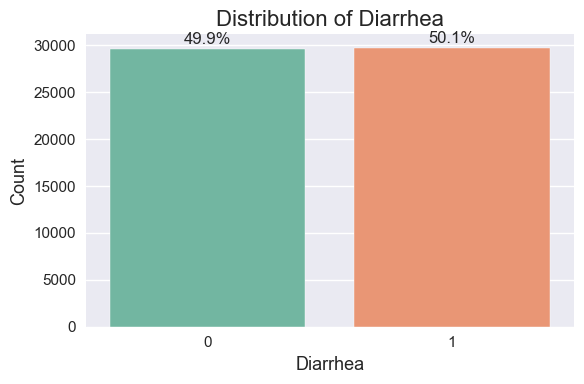

C:\Users\Marvella\AppData\Local\Temp\ipykernel_19512\3802682654.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=counts.index.astype(str), y=counts.values, palette="Set2")


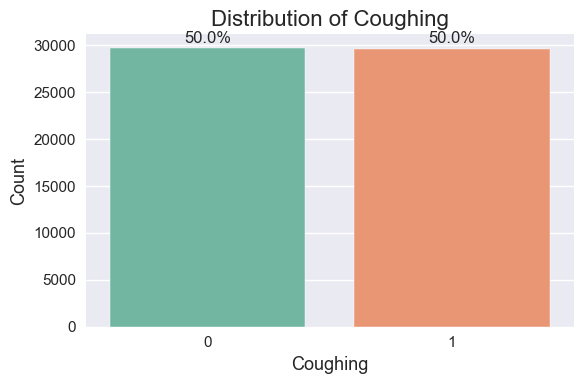

C:\Users\Marvella\AppData\Local\Temp\ipykernel_19512\3802682654.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=counts.index.astype(str), y=counts.values, palette="Set2")


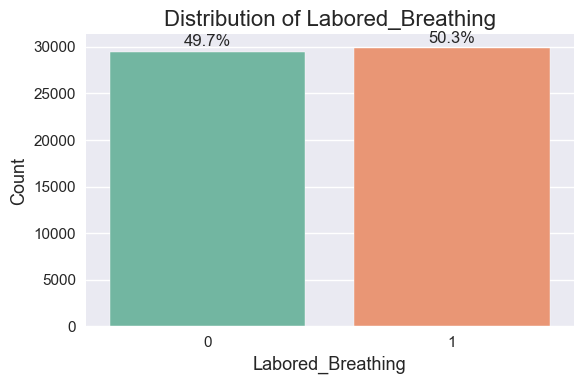

C:\Users\Marvella\AppData\Local\Temp\ipykernel_19512\3802682654.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=counts.index.astype(str), y=counts.values, palette="Set2")


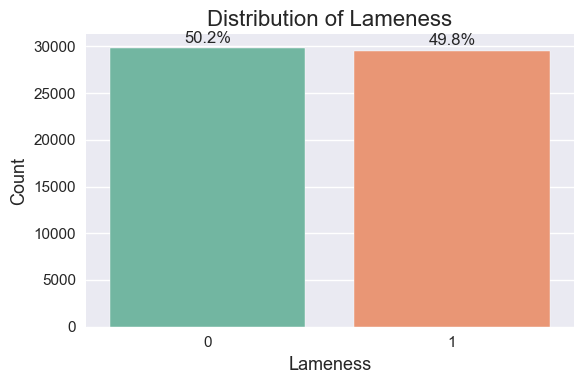

C:\Users\Marvella\AppData\Local\Temp\ipykernel_19512\3802682654.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=counts.index.astype(str), y=counts.values, palette="Set2")


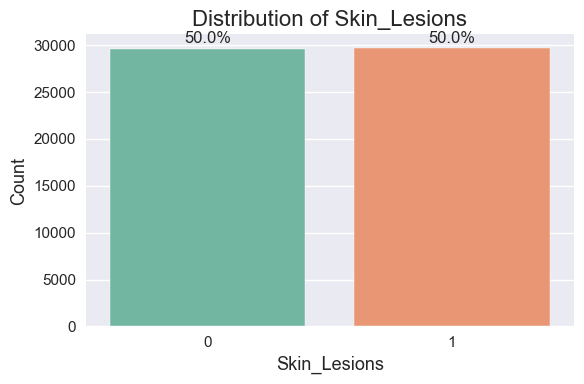

C:\Users\Marvella\AppData\Local\Temp\ipykernel_19512\3802682654.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=counts.index.astype(str), y=counts.values, palette="Set2")


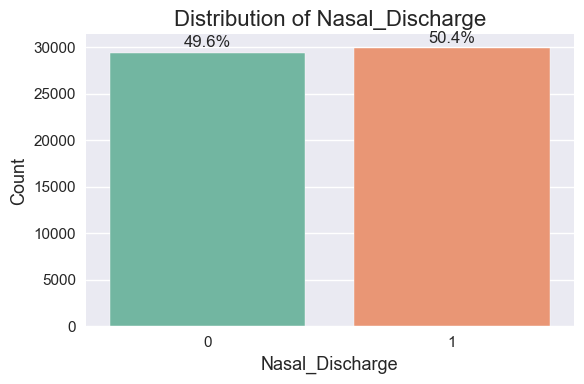

C:\Users\Marvella\AppData\Local\Temp\ipykernel_19512\3802682654.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=counts.index.astype(str), y=counts.values, palette="Set2")


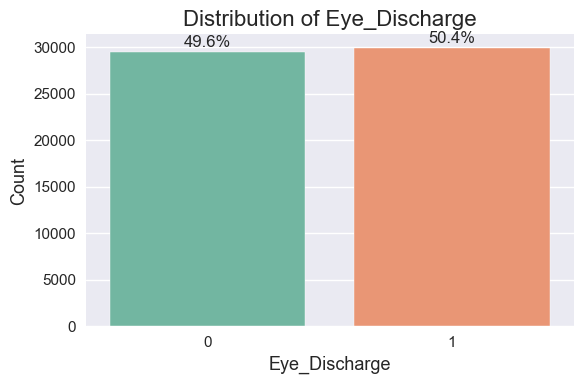

In [19]:
print("\n=== Binary Variables Distribution ===")
for col in binary_cols:
    plt.figure(figsize=(6,4))
    counts = df[col].value_counts().sort_index()
    ax = sns.barplot(x=counts.index.astype(str), y=counts.values, palette="Set2")
    
    total = len(df)
    for i, value in enumerate(counts.values):
        percentage = (value / total) * 100
        plt.text(i, value + total*0.01, f"{percentage:.1f}%", ha='center')
    
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

**Categorical Variable Distribution Analysis (Excluding Symptoms)**


CATEGORICAL VARIABLE DISTRIBUTION ANALYSIS


C:\Users\Marvella\AppData\Local\Temp\ipykernel_19512\3940931761.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


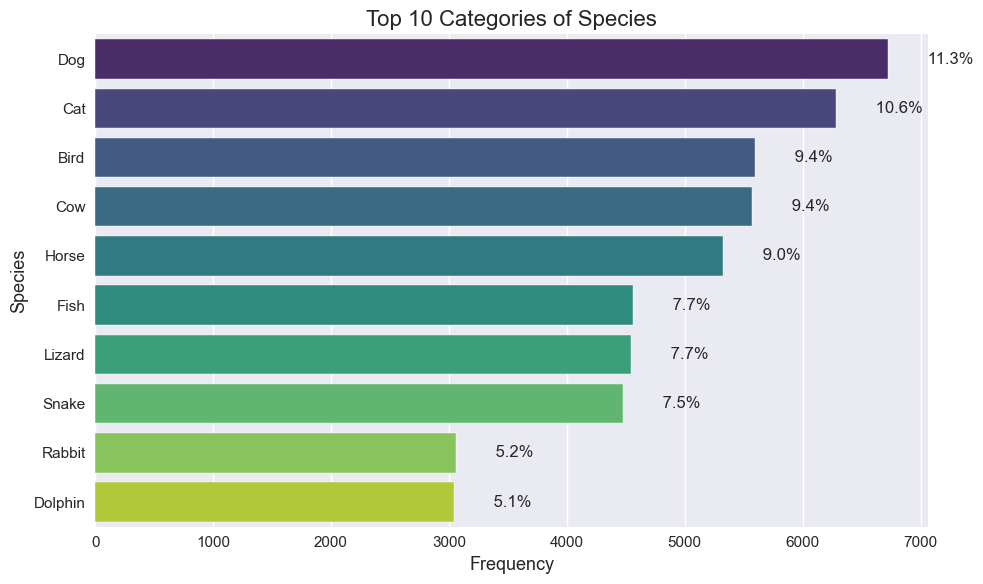

C:\Users\Marvella\AppData\Local\Temp\ipykernel_19512\3940931761.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


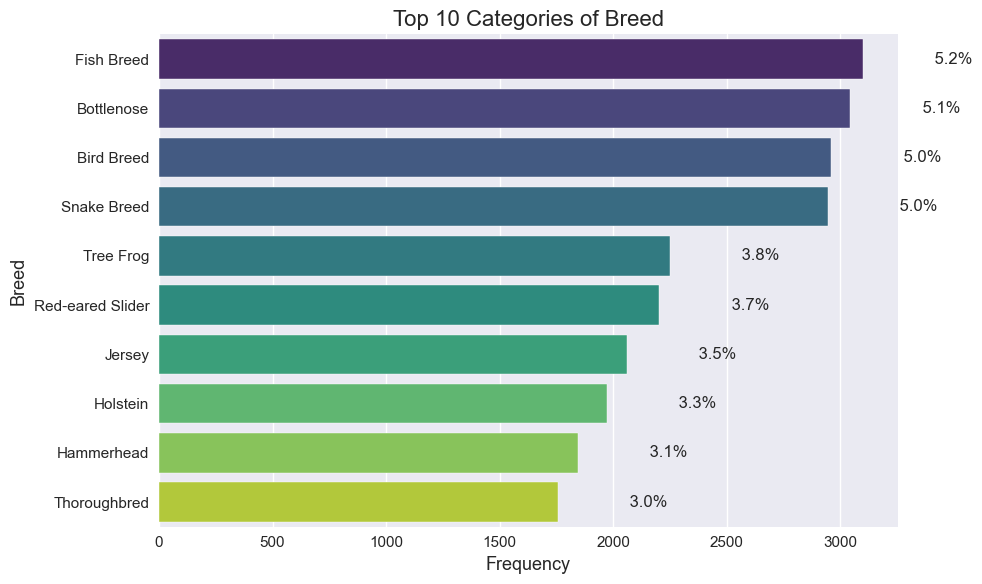

C:\Users\Marvella\AppData\Local\Temp\ipykernel_19512\3940931761.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


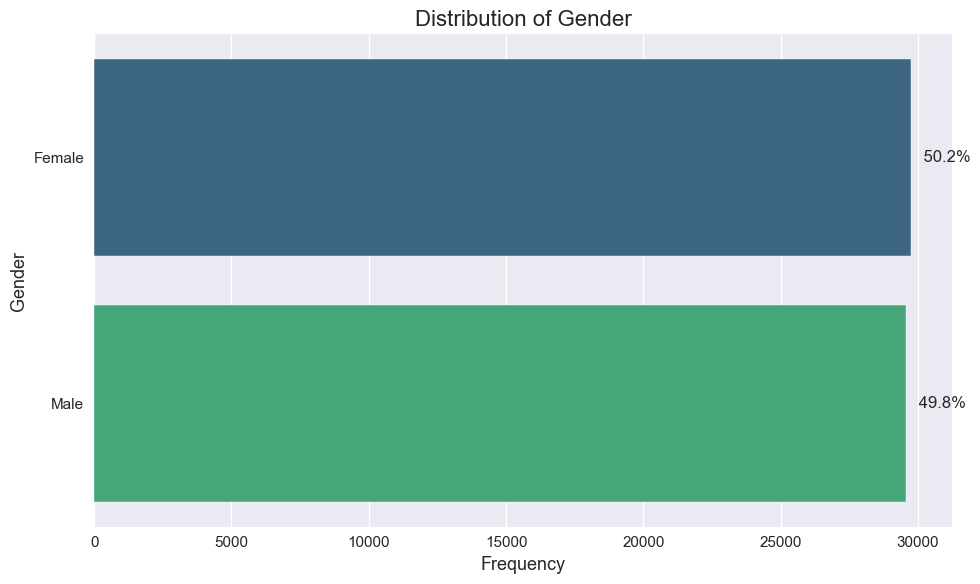

C:\Users\Marvella\AppData\Local\Temp\ipykernel_19512\3940931761.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


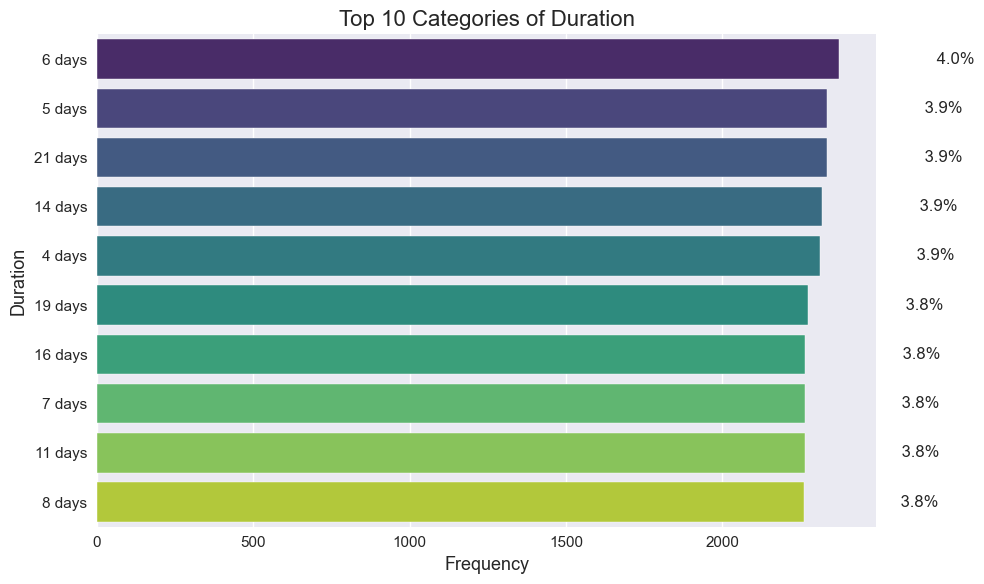

C:\Users\Marvella\AppData\Local\Temp\ipykernel_19512\3940931761.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(
C:\Users\Marvella\AppData\Local\Temp\ipykernel_19512\3940931761.py:43: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Marvella\AppData\Local\Temp\ipykernel_19512\3940931761.py:43: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()
C:\Users\Marvella\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


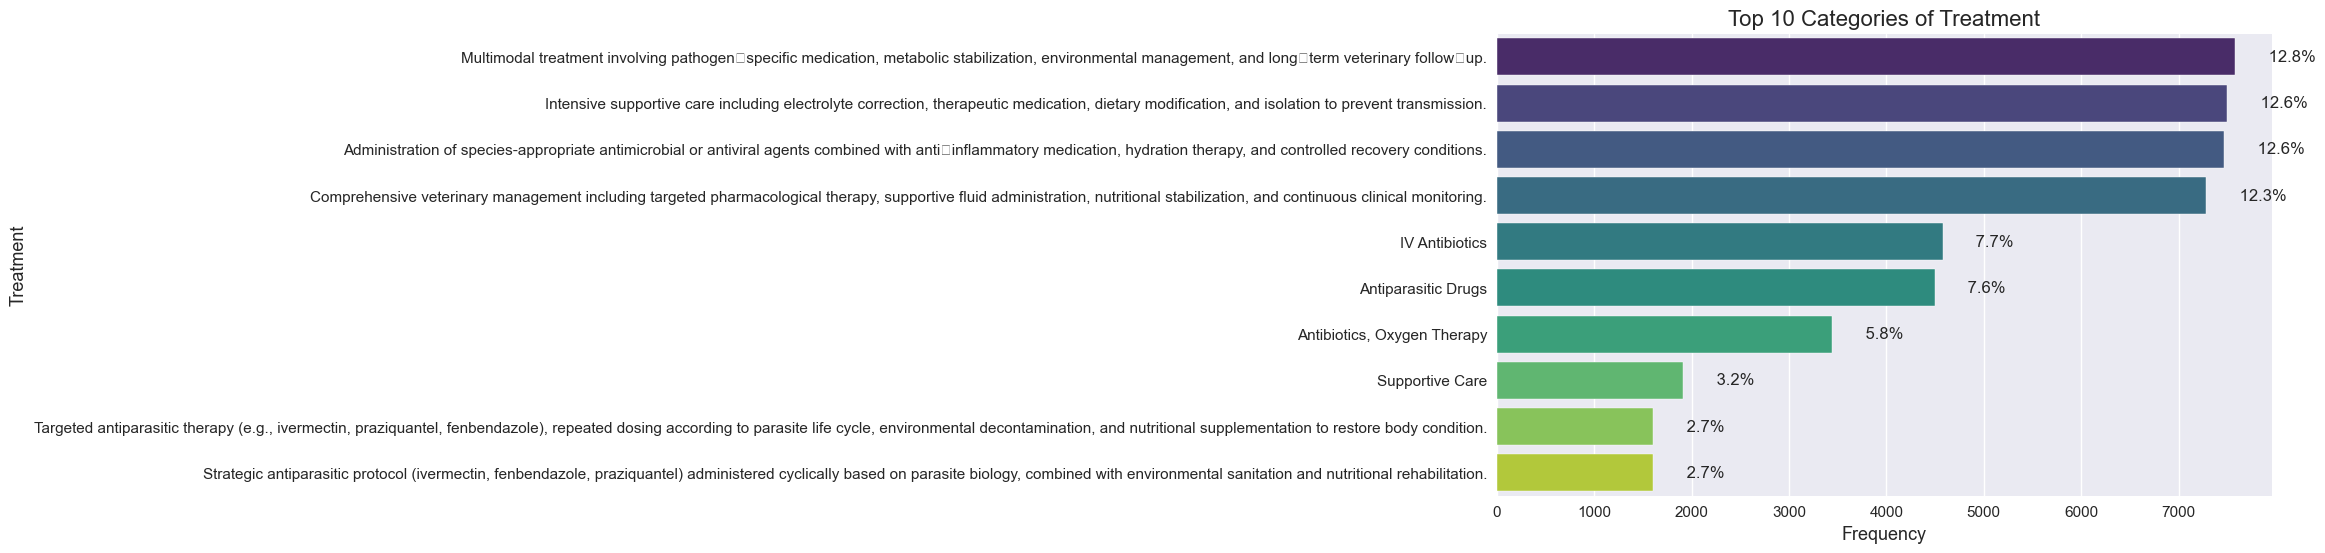

C:\Users\Marvella\AppData\Local\Temp\ipykernel_19512\3940931761.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(
C:\Users\Marvella\AppData\Local\Temp\ipykernel_19512\3940931761.py:43: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


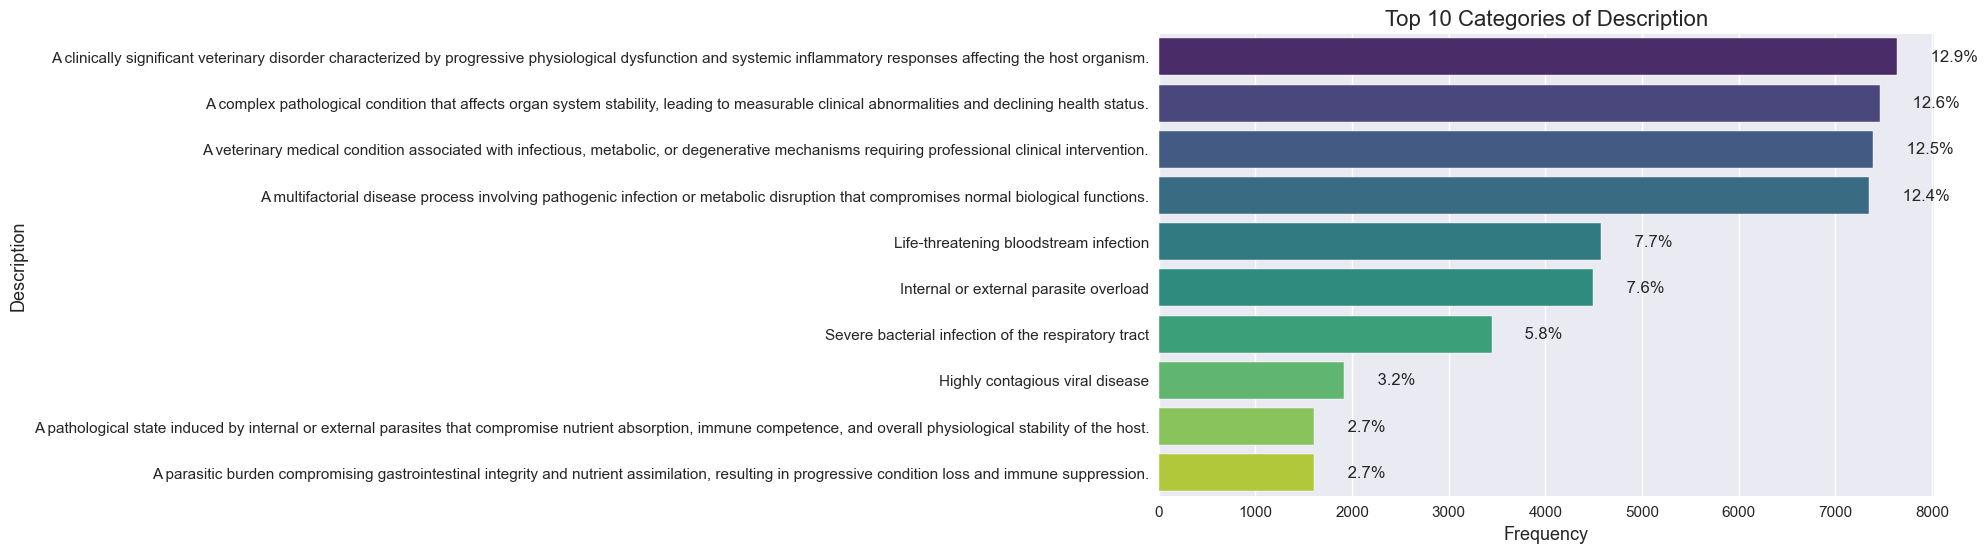

C:\Users\Marvella\AppData\Local\Temp\ipykernel_19512\3940931761.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


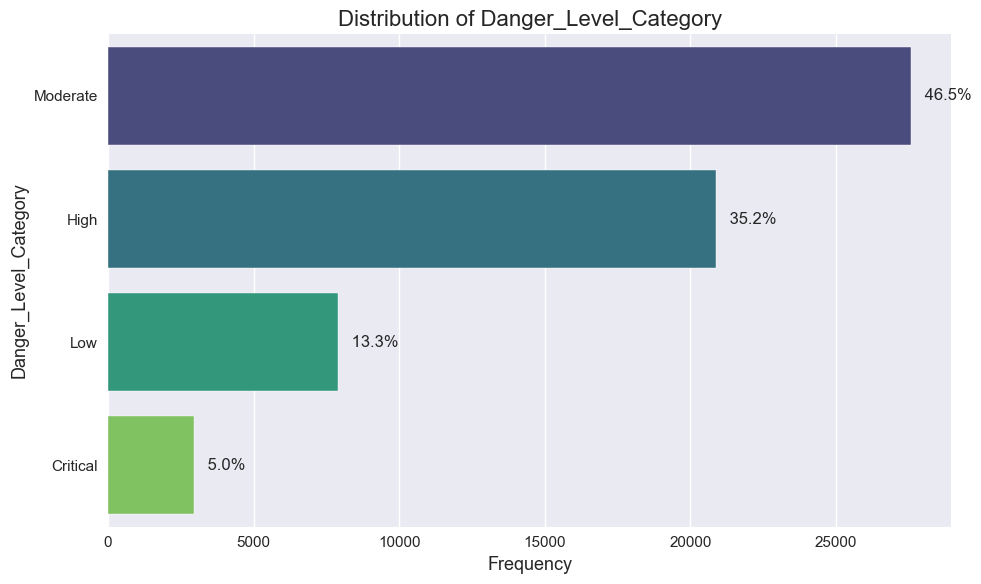

In [20]:
print("\n" + "="*60)
print("CATEGORICAL VARIABLE DISTRIBUTION ANALYSIS")
print("="*60)

# Identify symptom columns
symptom_cols = ['Symptom_1', 'Symptom_2', 'Symptom_3', 'Symptom_4']

# Filter categorical columns (excluding symptoms)
filtered_categorical_cols = [
    col for col in categorical_cols 
    if col not in symptom_cols and col != 'Disease_Prediction'
]

def plot_categories(column):
    unique_vals = df[column].nunique()
    
    # If few categories → plot all
    if unique_vals <= 10:
        data = df[column].value_counts()
        title = f"Distribution of {column}"
    else:
        data = df[column].value_counts().head(10)
        title = f"Top 10 Categories of {column}"
    
    total = len(df)
    
    plt.figure(figsize=(10, max(6, len(data)*0.4)))
    
    ax = sns.barplot(
        x=data.values,
        y=data.index,
        palette='viridis'
    )
    
    # Add percentage labels
    for i, value in enumerate(data.values):
        percentage = (value / total) * 100
        plt.text(value + total*0.005, i, f" {percentage:.1f}%", va='center')
    
    plt.title(title)
    plt.xlabel("Frequency")
    plt.ylabel(column)
    plt.tight_layout()
    plt.show()

# Apply visualization
for col in filtered_categorical_cols:
    plot_categories(col)

**Symptom Consolidation and Frequency Analysis**

*Step A - Merge Symptom Columns*

In [21]:
print("\n" + "="*60)
print("SYMPTOM CONSOLIDATED ANALYSIS")
print("="*60)

# Keep only existing symptom columns
symptom_cols = [col for col in symptom_cols if col in df.columns]

# Merge into single series
all_symptoms = pd.Series(
    df[symptom_cols].values.ravel()
).dropna()

print(f"Total symptom records after merging: {len(all_symptoms)}")
print(f"Unique symptoms: {all_symptoms.nunique()}")


SYMPTOM CONSOLIDATED ANALYSIS
Total symptom records after merging: 237256
Unique symptoms: 141


*Step B: Symptom Frequency Table*

In [22]:
symptom_counts = all_symptoms.value_counts()
symptom_percentages = (symptom_counts / len(all_symptoms) * 100).round(2)

print("\nTop 15 Most Frequent Symptoms:")
symptom_df = pd.DataFrame({
    'Symptom': symptom_counts.head(15).index,
    'Frequency': symptom_counts.head(15).values,
    'Percentage': symptom_percentages.head(15).values
})
display(symptom_df)


Top 15 Most Frequent Symptoms:


,Symptom,Frequency,Percentage
0,Lethargy,11299,4.76
1,Feeling nauseous,7227,3.05
2,Weakness,7107,3.00
3,Abdominal discomfort,6772,2.85
4,Exercise intolerance,6571,2.77
5,Muscle tremors,6435,2.71
6,Patchy hair loss,6084,2.56
7,Reduced appetite,6031,2.54
8,Seizure activity,6004,2.53
9,Behavioral changes,6004,2.53


*Step C: Professional Symptom Bar Chart*

C:\Users\Marvella\AppData\Local\Temp\ipykernel_19512\2070238155.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


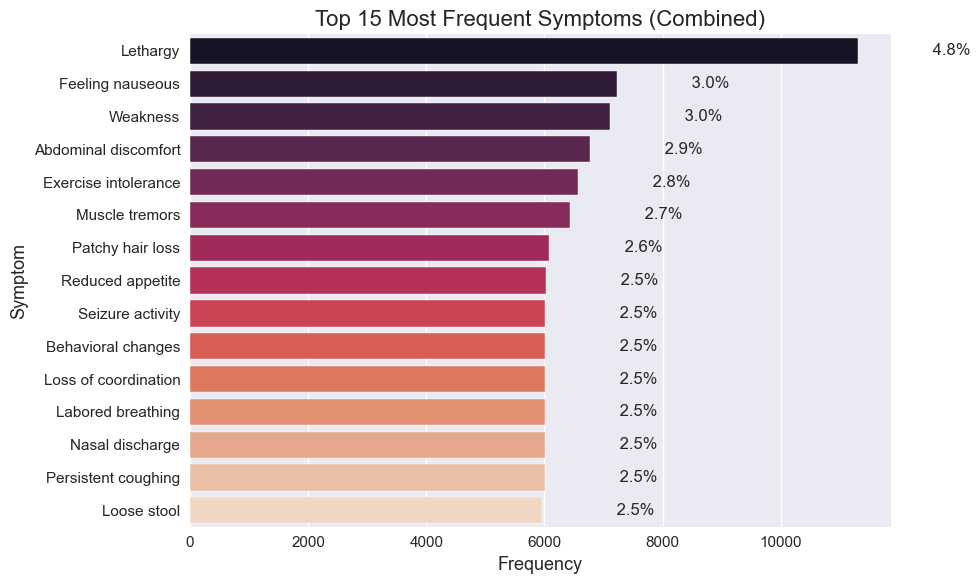

In [23]:
plt.figure(figsize=(10,6))
top_n = 15
data = symptom_counts.head(top_n)
total_symptoms = len(all_symptoms)

ax = sns.barplot(
    x=data.values,
    y=data.index,
    palette='rocket'
)

for i, value in enumerate(data.values):
    percentage = (value / total_symptoms) * 100
    plt.text(value + total_symptoms*0.005, i, f" {percentage:.1f}%", va='center')

plt.title(f"Top {top_n} Most Frequent Symptoms (Combined)")
plt.xlabel("Frequency")
plt.ylabel("Symptom")
plt.tight_layout()
plt.show()

*Step D: Symptom Frequency Polygon (Ranked Trend)*

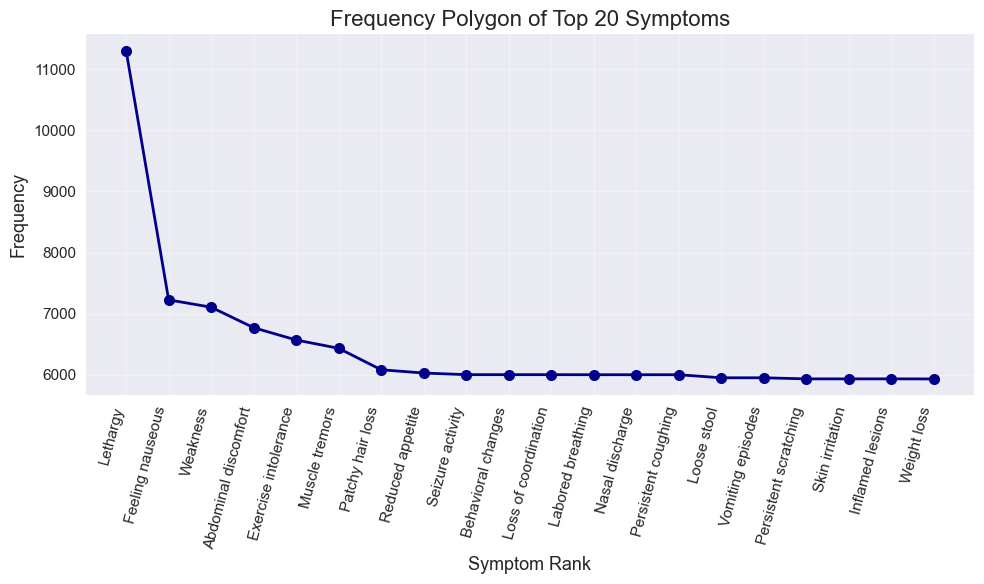

In [24]:
plt.figure(figsize=(10,6))
top_n = 20
data = symptom_counts.head(top_n)

plt.plot(
    range(1, len(data)+1),
    data.values,
    marker='o',
    linewidth=2,
    markersize=8,
    color='darkblue'
)

plt.xticks(
    range(1, len(data)+1),
    data.index,
    rotation=75,
    ha='right'
)

plt.title("Frequency Polygon of Top 20 Symptoms")
plt.xlabel("Symptom Rank")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Correlation Analysis of Numerical Features**


CORRELATION ANALYSIS


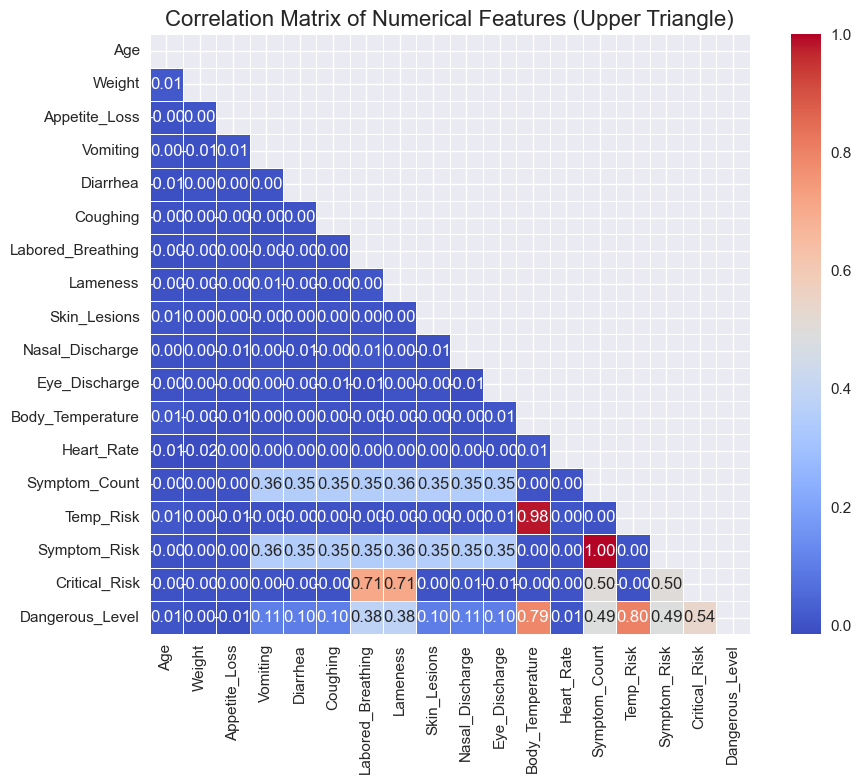

In [25]:
print("\n" + "="*60)
print("CORRELATION ANALYSIS")
print("="*60)

if len(numerical_cols) > 1:
    # Upper triangle heatmap (cleaner)
    plt.figure(figsize=(10,8))
    corr_matrix = df[numerical_cols].corr()
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    
    sns.heatmap(corr_matrix,
                mask=mask,
                annot=True,
                fmt=".2f",
                cmap="coolwarm",
                linewidths=0.5,
                square=True)
    
    plt.title("Correlation Matrix of Numerical Features (Upper Triangle)")
    plt.tight_layout()
    plt.show()

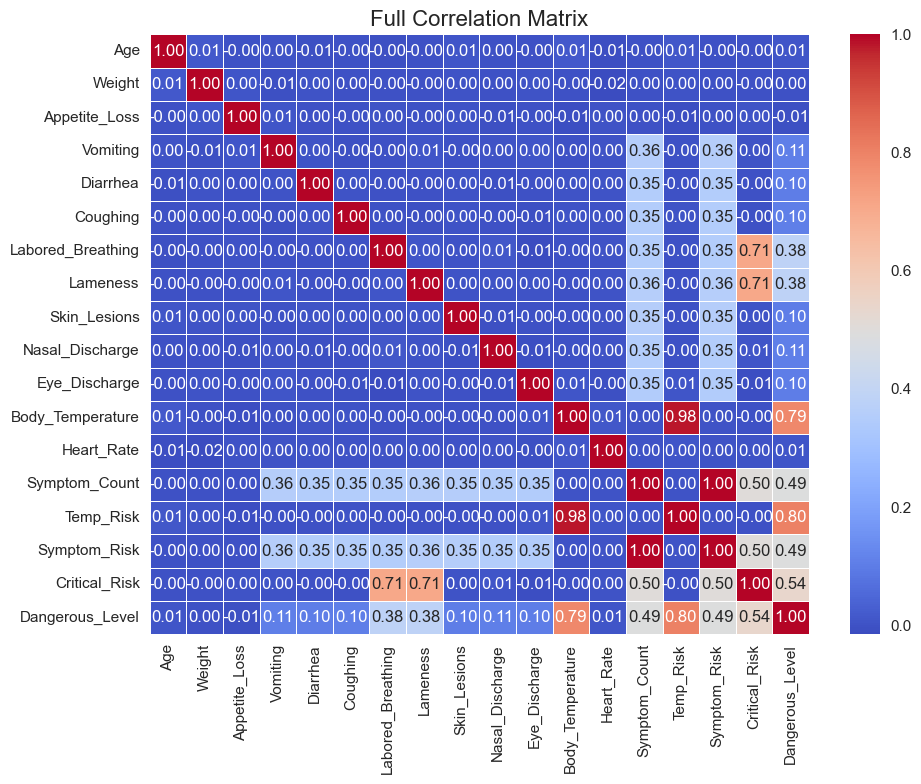

In [26]:
plt.figure(figsize=(10,8))

sns.heatmap(df[numerical_cols].corr(),
            annot=True,
            fmt=".2f",
            cmap="coolwarm",
            linewidths=0.5)

plt.title("Full Correlation Matrix")
plt.tight_layout()
plt.show()

**Feature-Target Relationship Analysis**


FEATURE-TARGET RELATIONSHIP ANALYSIS
===== CORRELATION WITH DANGEROUS LEVEL =====


,Feature,Correlation
0,Temp_Risk,0.802
1,Body_Temperature,0.789
2,Critical_Risk,0.539
3,Symptom_Risk,0.491
4,Symptom_Count,0.491
5,Labored_Breathing,0.382
6,Lameness,0.381
7,Nasal_Discharge,0.105
8,Vomiting,0.105
9,Coughing,0.105


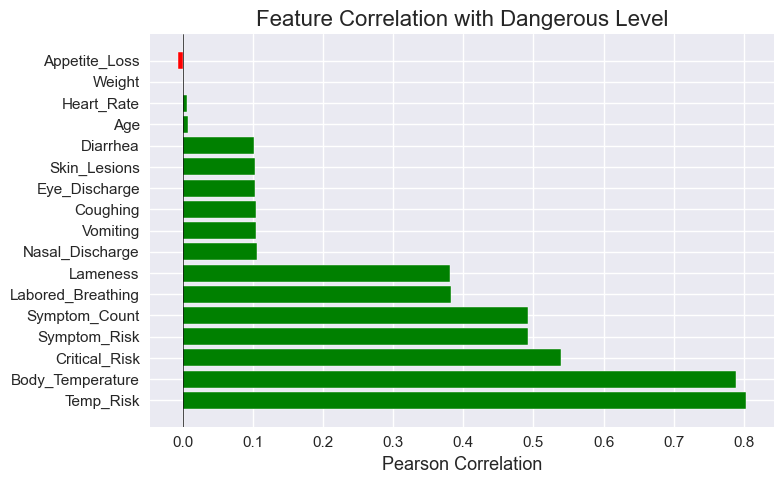

In [27]:
print("\n" + "="*60)
print("FEATURE-TARGET RELATIONSHIP ANALYSIS")
print("="*60)

if 'Dangerous_Level' in numerical_cols:
    print("===== CORRELATION WITH DANGEROUS LEVEL =====")
    
    corr_with_target = df[numerical_cols].corr()['Dangerous_Level'].drop('Dangerous_Level').sort_values(ascending=False)
    
    corr_df = pd.DataFrame({
        'Feature': corr_with_target.index,
        'Correlation': corr_with_target.values.round(3)
    })
    display(corr_df)
    
    # Visualize
    plt.figure(figsize=(8,5))
    colors = ['red' if x < 0 else 'green' for x in corr_with_target.values]
    plt.barh(range(len(corr_with_target)), corr_with_target.values, color=colors)
    plt.yticks(range(len(corr_with_target)), corr_with_target.index)
    plt.xlabel("Pearson Correlation")
    plt.title("Feature Correlation with Dangerous Level")
    plt.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
    plt.tight_layout()
    plt.show()

**Multicollinearity Assessment**

In [28]:
print("\n" + "="*60)
print("MULTICOLLINEARITY CHECK")
print("="*60)

corr_matrix = df[numerical_cols].corr().abs()

# Select only strong correlations (excluding self-correlation)
strong_pairs = (
    corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    .stack()
)

strong_pairs = strong_pairs[strong_pairs > 0.8]

if len(strong_pairs) > 0:
    print("High correlations detected (|r| > 0.8):")
    for idx, value in strong_pairs.items():
        print(f"  • {idx[0]} ↔ {idx[1]}: {value:.3f}")
else:
    print("No high multicollinearity detected.")


MULTICOLLINEARITY CHECK
High correlations detected (|r| > 0.8):
  • Body_Temperature ↔ Temp_Risk: 0.983
  • Symptom_Count ↔ Symptom_Risk: 1.000
  • Temp_Risk ↔ Dangerous_Level: 0.802


**Outlier Detection and Distribution Assessment**

*Physiological Variable*

===== PHYSIOLOGICAL VARIABLE OUTLIER ANALYSIS =====


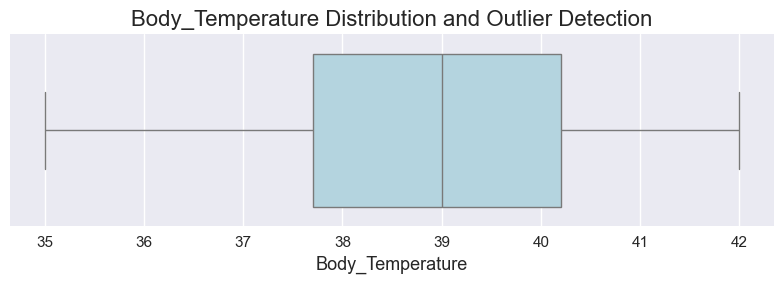

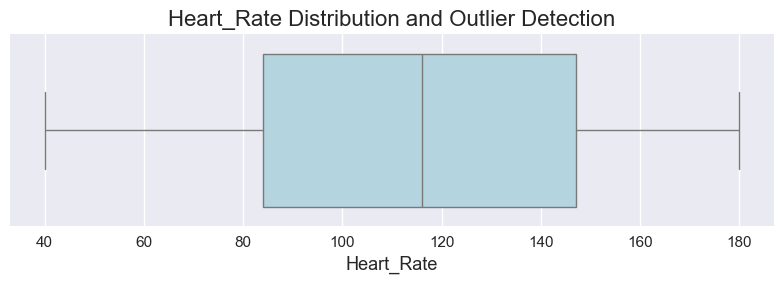

In [29]:
print("===== PHYSIOLOGICAL VARIABLE OUTLIER ANALYSIS =====")
general_cols = ['Body_Temperature', 'Heart_Rate']

for col in general_cols:
    if col in df.columns:
        plt.figure(figsize=(8,3))
        sns.boxplot(x=df[col], color='lightblue')
        plt.title(f"{col} Distribution and Outlier Detection")
        plt.xlabel(col)
        plt.tight_layout()
        plt.show()

*Weight Distribution Across Species*

===== WEIGHT DISTRIBUTION PER SPECIES =====


C:\Users\Marvella\AppData\Local\Temp\ipykernel_19512\2437686084.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


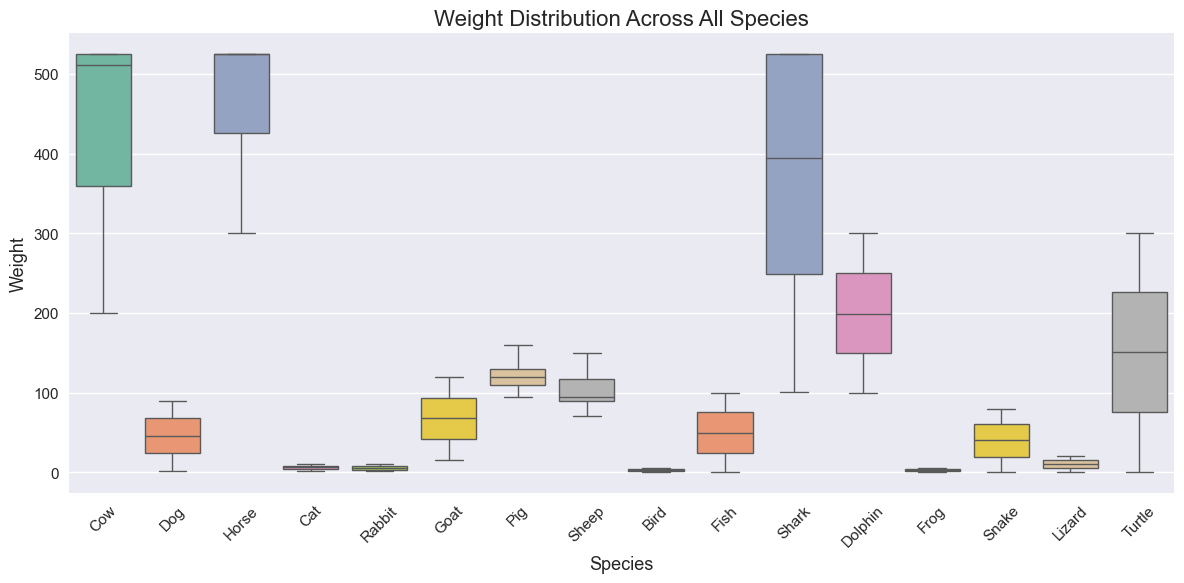

In [30]:
print("===== WEIGHT DISTRIBUTION PER SPECIES =====")

if 'Weight' in df.columns and 'Species' in df.columns:
    
    # Overall weight distribution
    plt.figure(figsize=(12,6))
    sns.boxplot(
        data=df,
        x='Species',
        y='Weight',
        palette='Set2'
    )
    plt.xticks(rotation=45)
    plt.title("Weight Distribution Across All Species")
    plt.xlabel("Species")
    plt.ylabel("Weight")
    plt.tight_layout()
    plt.show()

*Weight Distribution for Top Species*

C:\Users\Marvella\AppData\Local\Temp\ipykernel_19512\1698312842.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


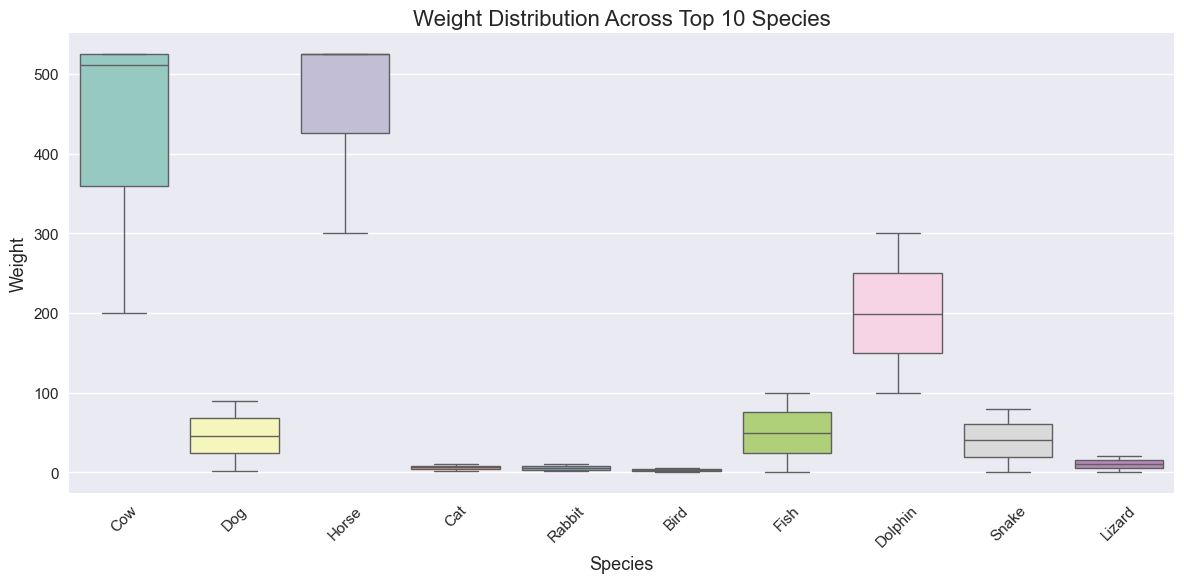

In [31]:
top_species = df['Species'].value_counts().head(10).index
filtered_df = df[df['Species'].isin(top_species)]
    
plt.figure(figsize=(12,6))
sns.boxplot(
    data=filtered_df,
    x='Species',
    y='Weight',
    palette='Set3'
)

plt.xticks(rotation=45)
plt.title("Weight Distribution Across Top 10 Species")
plt.xlabel("Species")
plt.ylabel("Weight")
plt.tight_layout()
plt.show()

*Individual Species Weight Profiles*

===== WEIGHT DISTRIBUTION ANALYSIS PER SPECIES =====


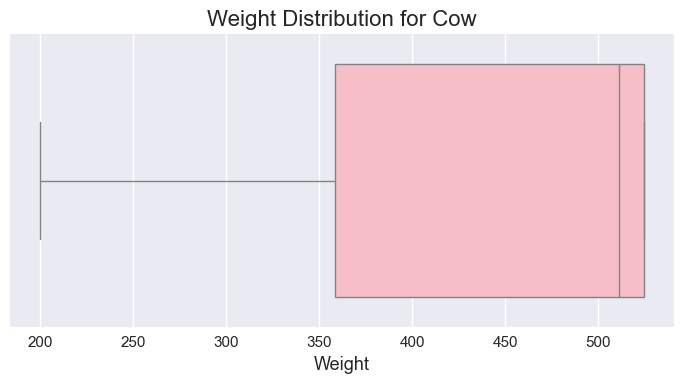

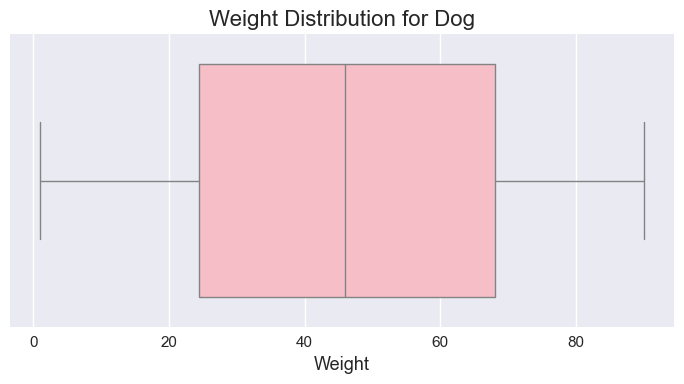

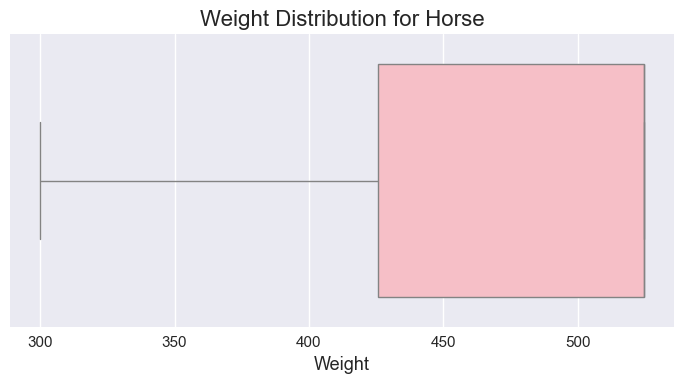

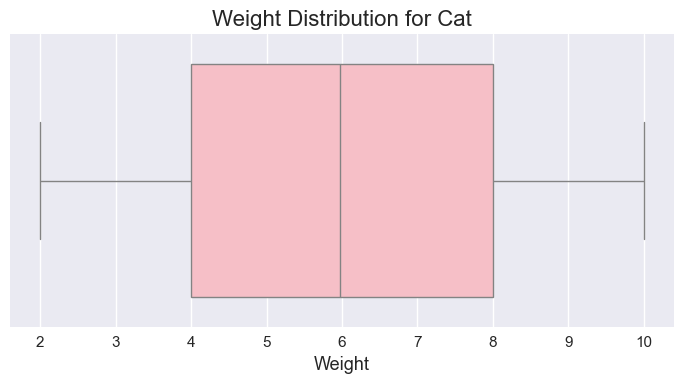

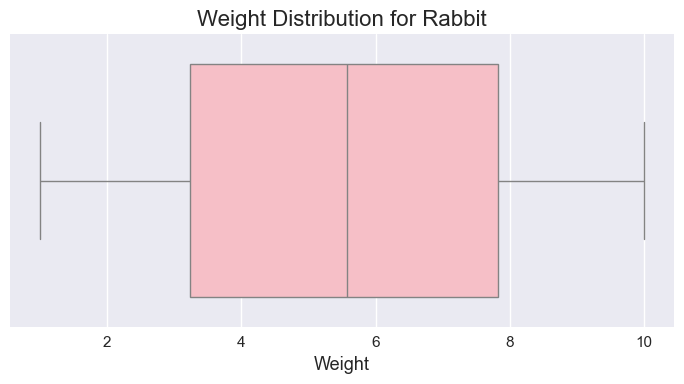

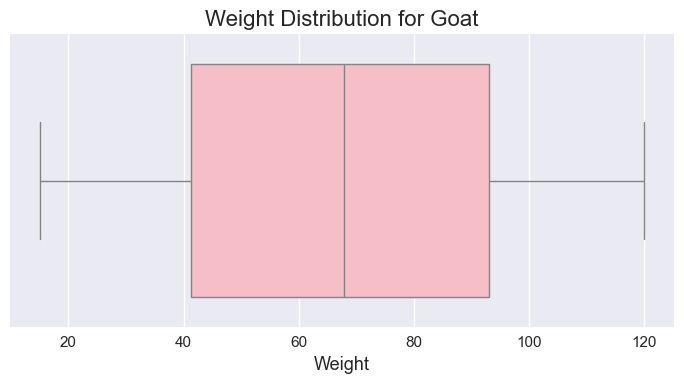

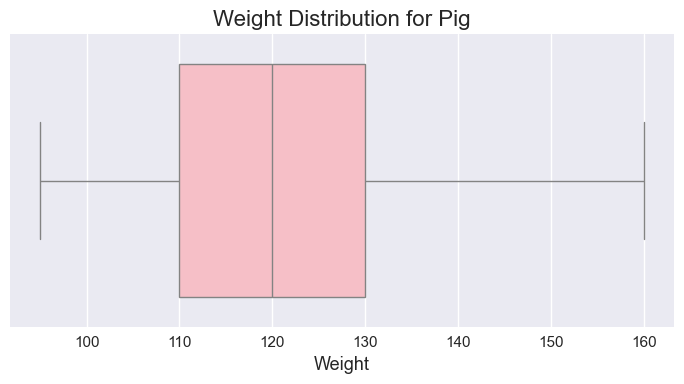

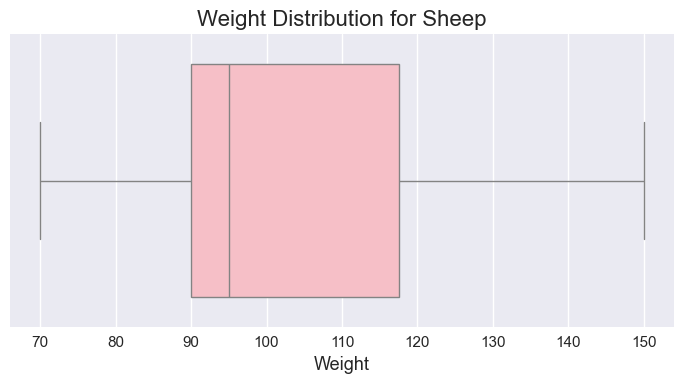

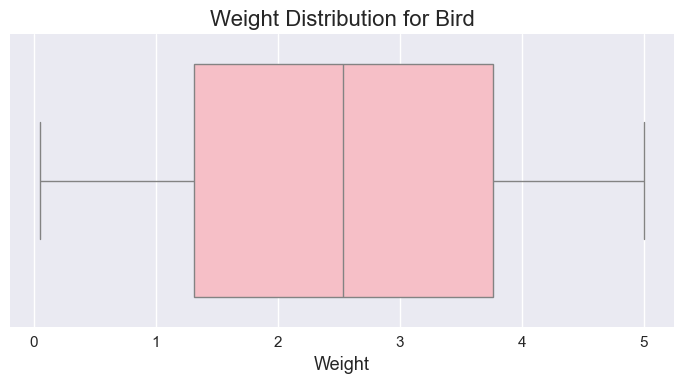

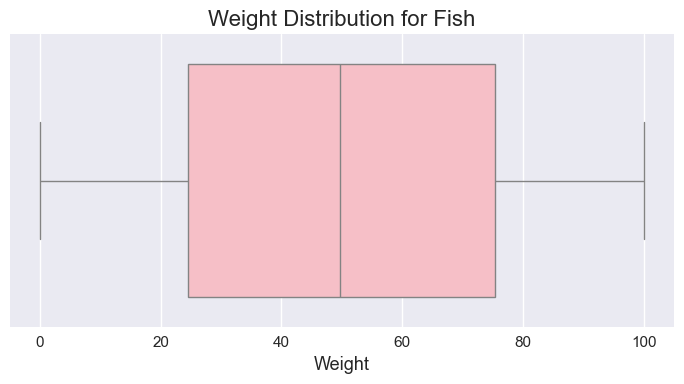

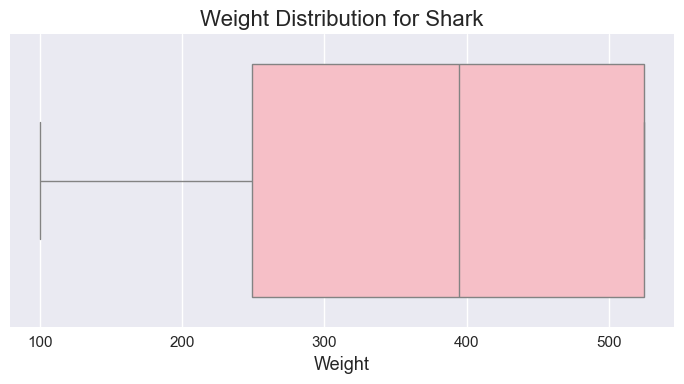

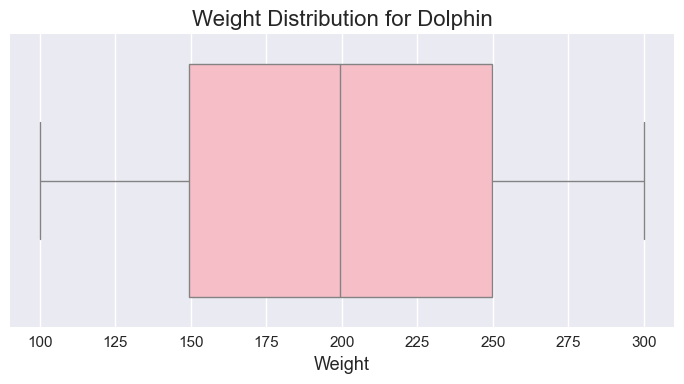

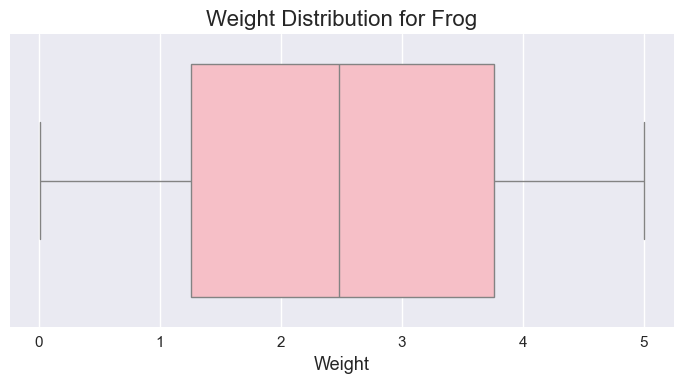

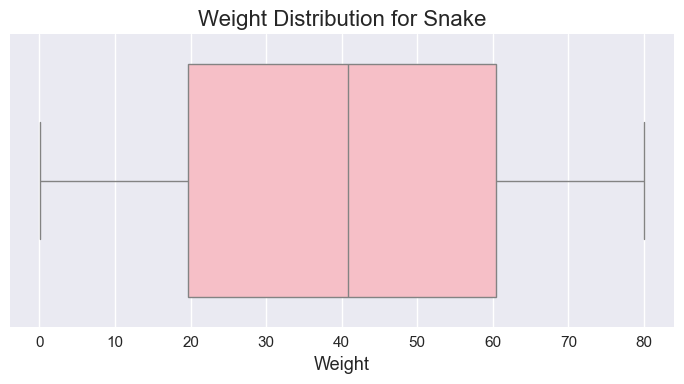

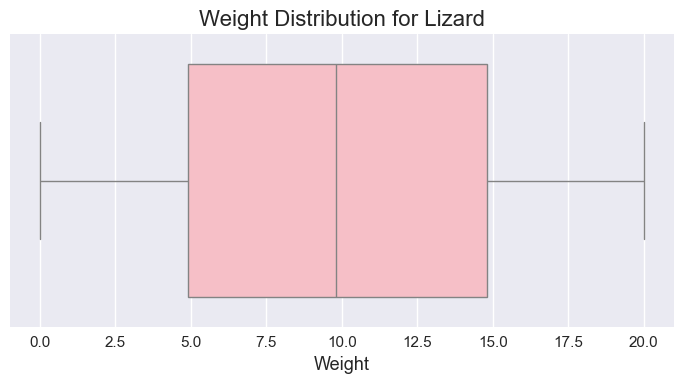

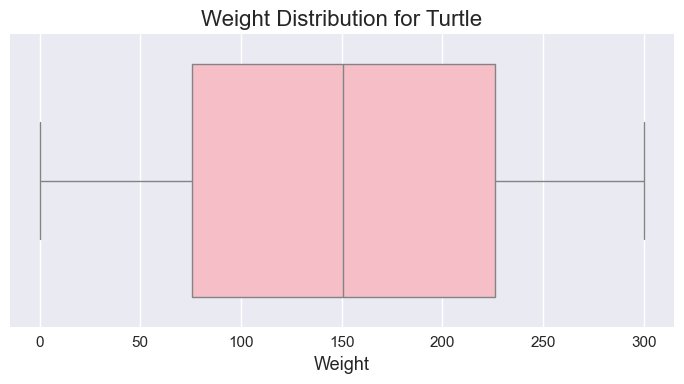

In [32]:
print("===== WEIGHT DISTRIBUTION ANALYSIS PER SPECIES =====")

if 'Weight' in df.columns and 'Species' in df.columns:
    
    species_list = df['Species'].dropna().unique()
    
    for species in species_list:
        species_data = df[df['Species'] == species]['Weight'].dropna()
        
        if len(species_data) > 0:
            plt.figure(figsize=(7,4))
            
            sns.boxplot(x=species_data, color='lightpink')
            
            plt.title(f"Weight Distribution for {species}")
            plt.xlabel("Weight")
            plt.tight_layout()
            plt.show()

**Bivariate Analysis**

*Symptom Count vs. Dangerous Level*


===== Symptom Count vs Dangerous Level =====


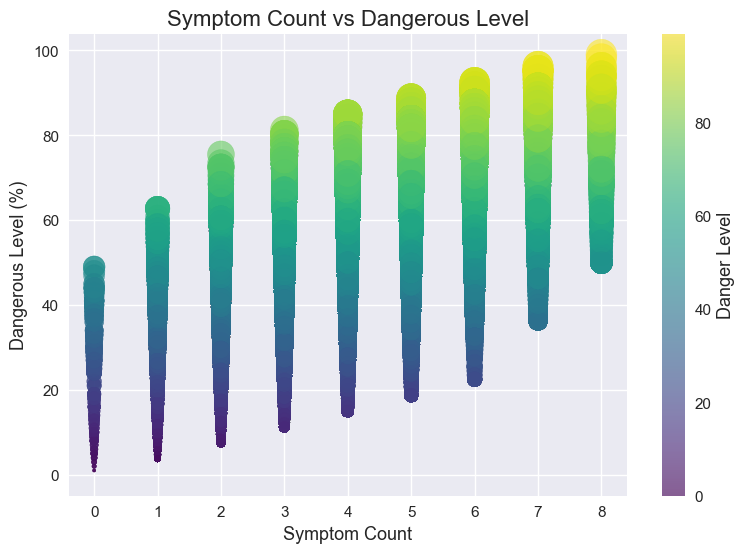

In [33]:
if 'Symptom_Count' in df.columns and 'Dangerous_Level' in df.columns:
    print("\n===== Symptom Count vs Dangerous Level =====")
    
    plt.figure(figsize=(9,6))
    scatter = plt.scatter(df['Symptom_Count'],
                df['Dangerous_Level'],
                s=df['Dangerous_Level']*5,
                c=df['Dangerous_Level'],
                cmap="viridis",
                alpha=0.6)
    
    plt.colorbar(scatter, label="Danger Level")
    plt.xlabel("Symptom Count")
    plt.ylabel("Dangerous Level (%)")
    plt.title("Symptom Count vs Dangerous Level")

*Calculate Correlation*

In [34]:
corr, p_value = pearsonr(df['Symptom_Count'].dropna(), df['Dangerous_Level'].dropna())

print(f"Pearson correlation: {corr:.3f}")
print(f"P-value: {p_value:.4f}")
print(f"Statistically significant: {'Yes' if p_value < 0.05 else 'No'}")

Pearson correlation: 0.491
P-value: 0.0000
Statistically significant: Yes


*Temperature vs. Danger Level*


===== Body Temperature by Danger Level =====


C:\Users\Marvella\AppData\Local\Temp\ipykernel_19512\2461942461.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Danger_Level_Category',


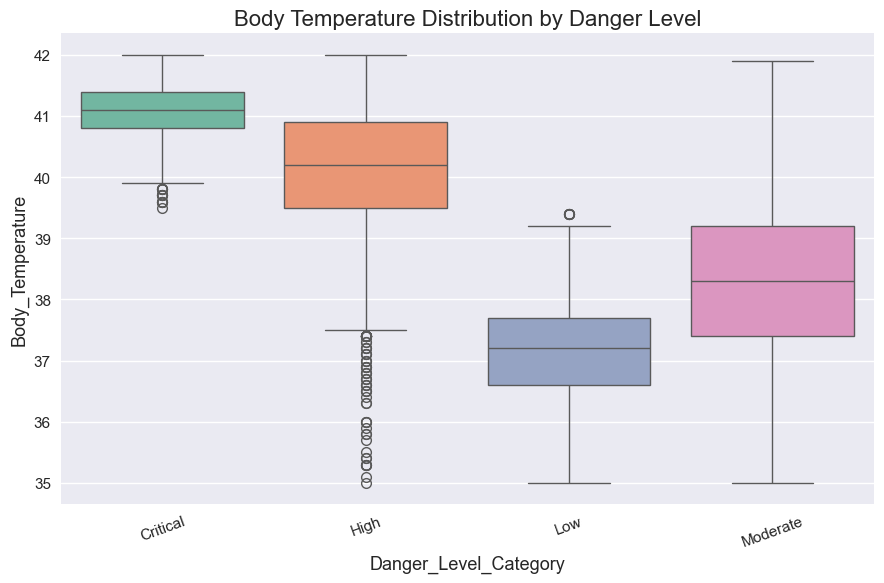

In [35]:
if 'Danger_Level_Category' in df.columns and 'Body_Temperature' in df.columns:
    print("\n===== Body Temperature by Danger Level =====")
    
    plt.figure(figsize=(9,6))
    order = sorted(df['Danger_Level_Category'].dropna().unique())
    sns.boxplot(data=df, x='Danger_Level_Category',
                   y='Body_Temperature', 
                   order=order,
                   palette="Set2")
    plt.xticks(rotation=20)
    plt.title("Body Temperature Distribution by Danger Level")
    plt.tight_layout()
    plt.show()

**Statistical Relationship Testing**

In [36]:
print("\n" + "="*60)
print("STATISTICAL HYPOTHESIS TESTING")
print("="*60)

if 'Danger_Level_Category' in df.columns and 'Disease_Prediction' in df.columns:
    print("\n===== Chi-Square Test: Danger Level vs Disease Prediction =====")
    
    # Create contingency table (using top diseases to avoid sparse cells)
    top_diseases = df['Disease_Prediction'].value_counts().head(20).index
    df_subset = df[df['Disease_Prediction'].isin(top_diseases)]
    
    cont_table = pd.crosstab(df_subset['Danger_Level_Category'],
                             df_subset['Disease_Prediction'])
    
    chi2, p, dof, expected = chi2_contingency(cont_table)
    
    print("Chi-Square Statistic:", round(chi2,2))
    print("Degrees of Freedom:", dof)
    print("P-value:", round(p,5))
    
    if p < 0.05:
        print("✔ Significant relationship detected between Danger Level and Disease Prediction.")
        
        # Calculate Cramer's V for effect size
        n = cont_table.sum().sum()
        cramer_v = np.sqrt(chi2 / (n * (min(cont_table.shape) - 1)))
        print(f"Effect size (Cramer's V): {cramer_v:.3f}")
    else:
        print("✖ No statistically significant relationship detected.")


STATISTICAL HYPOTHESIS TESTING

===== Chi-Square Test: Danger Level vs Disease Prediction =====
Chi-Square Statistic: 99.67
Degrees of Freedom: 57
P-value: 0.00041
✔ Significant relationship detected between Danger Level and Disease Prediction.
Effect size (Cramer's V): 0.030


**Dataset Comparison & Data Gathering**

In [37]:
comparison_summary = pd.DataFrame({
    "Dataset": ["DF1", "DF2", "DF3", 'DF4',"Merged"],
    "Records": [len(df1), len(df2), len(df3), len(df4), len(df)],
    "Unique Diseases": [
        df1['Disease_Prediction'].nunique(),
        df2['Disease_Prediction'].nunique(),
        df3['Disease_Prediction'].nunique(),
        df4['Disease_Prediction'].nunique(),
        df['Disease_Prediction'].nunique()
    ],
    "Unique Species": [
        df1['Animal_Type'].nunique(),
        df2['Species'].nunique(),
        df3['Species'].nunique(),
        df4['Species'].nunique(),
        df['Species'].nunique()
    ]
})

display(comparison_summary)

,Dataset,Records,Unique Diseases,Unique Species
0,DF1,431,139,8
1,DF2,40000,5,17126
2,DF3,14000,0,14000
3,DF4,30000,99,10
4,Merged,59314,162,16


**Clinical Insight Aggregation**

In [38]:
print("\n" + "="*60)
print("CLINICAL INSIGHT AGGREGATION")
print("="*60)

clinical_summary = df.groupby('Disease_Prediction').agg({
    'Body_Temperature': 'mean',
    'Heart_Rate': 'mean',
    'Dangerous_Level': 'mean',
    'Symptom_Count': 'mean'
}).round(2).sort_values('Dangerous_Level', ascending=False)

print("\nTop 10 Diseases by Dangerous Level (Clinical Profile):")
display(clinical_summary.head(10))


CLINICAL INSIGHT AGGREGATION

Top 10 Diseases by Dangerous Level (Clinical Profile):


,Body_Temperature,Heart_Rate,Dangerous_Level,Symptom_Count
Disease_Prediction,,,,
Scrapie Disease,39.55,82.50,73.62,7.50
Porcine Epidemic Diarrhea Virus,39.50,105.00,71.25,7.00
Viral Hemorrhagic Disease,39.20,130.00,68.25,7.00
African Swine Fever,39.45,97.50,67.00,6.00
Canine Cough,39.30,120.00,65.50,6.00
Equine Lyme Disease,39.60,78.00,64.75,5.00
Equine Metabolic Syndrome,39.50,93.50,64.38,6.50
Swine Fever,39.43,101.67,63.50,6.00
Bovine Respiratory Disease Complex,39.50,81.67,62.92,5.67


**Summary of Data Understanding Findings**

In [39]:
print("\n" + "="*60)
print("FINAL DATA UNDERSTANDING SUMMARY")
print("="*60)

print("Total Records:", len(df))
print("Unique Species:", df['Species'].nunique())
print("Unique Diseases:", df['Disease_Prediction'].nunique())
print("Most Common Disease:", df['Disease_Prediction'].mode()[0])
print("Highest Risk Disease:",
      df.groupby('Disease_Prediction')['Dangerous_Level'].mean().idxmax())
print("Class Imbalance Ratio:", round(imbalance_ratio, 2))



FINAL DATA UNDERSTANDING SUMMARY
Total Records: 59314
Unique Species: 16
Unique Diseases: 162
Most Common Disease: Parasitic Infestation
Highest Risk Disease: Scrapie Disease
Class Imbalance Ratio: 8941.0
